In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import zipfile, os

# Zip dosyalarının Drive'daki yolu
base = '/content/drive/MyDrive'

datasets = {
    'afdb' : 'mit-bih-atrial-fibrillation-database-1.0.0.zip',
    'nsrdb': 'mit-bih-normal-sinus-rhythm-database-1.0.0.zip',
    'afpdb': 'paf-prediction-challenge-database-1.0.0.zip',
}

# Her birini /content/data/ altına aç
for db_name, zip_file in datasets.items():
    zip_path = os.path.join(base, zip_file)
    out_path = f'/content/data/{db_name}'
    os.makedirs(out_path, exist_ok=True)
    print(f'Açılıyor: {zip_file} ...')
    with zipfile.ZipFile(zip_path, 'r') as z:
        z.extractall(out_path)
    print(f'✓ {db_name} hazır')

Mounted at /content/drive
Açılıyor: mit-bih-atrial-fibrillation-database-1.0.0.zip ...
✓ afdb hazır
Açılıyor: mit-bih-normal-sinus-rhythm-database-1.0.0.zip ...
✓ nsrdb hazır
Açılıyor: paf-prediction-challenge-database-1.0.0.zip ...
✓ afpdb hazır


In [ ]:
# ════════════════════════════════════════════════════════
# HÜCRE 1 — Drive & Kurulum
# ════════════════════════════════════════════════════════
from google.colab import drive
drive.mount('/content/drive')
import zipfile, os

base = '/content/drive/MyDrive'
datasets = {
    'afdb' : 'mit-bih-atrial-fibrillation-database-1.0.0.zip',
    'nsrdb': 'mit-bih-normal-sinus-rhythm-database-1.0.0.zip',
    'afpdb': 'paf-prediction-challenge-database-1.0.0.zip',
}
for db_name, zip_file in datasets.items():
    zip_path = os.path.join(base, zip_file)
    out_path = f'/content/data/{db_name}'
    os.makedirs(out_path, exist_ok=True)
    if len(os.listdir(out_path)) > 2:
        print(f'✓ {db_name} zaten mevcut'); continue
    print(f'Açılıyor: {zip_file} ...')
    with zipfile.ZipFile(zip_path, 'r') as z:
        z.extractall(out_path)
    print(f'✓ {db_name} hazır')

!pip install wfdb pywavelets scikit-learn xgboost lightgbm shap tqdm statsmodels -q

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Açılıyor: mit-bih-atrial-fibrillation-database-1.0.0.zip ...
✓ afdb hazır
Açılıyor: mit-bih-normal-sinus-rhythm-database-1.0.0.zip ...
✓ nsrdb hazır
Açılıyor: paf-prediction-challenge-database-1.0.0.zip ...
✓ afpdb hazır
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 18.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 159.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.3 which is incompatible.
cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.3 which is incompatible.
bqplot 0.12.45 requires pandas<3.0.0,>=1.0.0, b

In [ ]:
# ════════════════════════════════════════════════════════
# HÜCRE 2 — Import & Ayarlar
#
# UYGULANAN DÜZELTMELERİN TAMAMI:
#
#  [DÜZ-1] WAVELET = "db8"   — ablasyon: en yüksek F1 (%85.98)
#  [DÜZ-2] DWT_LEVELS = 4    — ablasyon: en yüksek F1 (%87.04)
#  [DÜZ-3] GroupShuffleSplit + GroupKFold — kayıt bazlı, sızıntı yok
#  [DÜZ-4] SVM kaldırıldı — adil olmayan karşılaştırma
#  [DÜZ-5] McNemar testi eklendi — model farkları istatistiksel
#  [DÜZ-6] SHAP sayısal çıktısı eklendi — band bazlı değerler
#  [DÜZ-7] Confusion matrix karışma analizi eklendi
#  [DÜZ-8] CWT metodoloji notu netleştirildi
#  [DÜZ-8] CWT yalnızca görsel doğrulama aracı — öznitelik çıkarımında kullanılmaz
#  [YENİ-2] Erken tespit ana deneyle birleştirildi — tek split
#  [YENİ-3] DWT vs WPD adil karşılaştırma — max_depth optimizasyonu
# ════════════════════════════════════════════════════════
import os, warnings, json, time
import numpy as np
import pandas as pd
import pywt, wfdb
from scipy.signal import resample as scipy_resample
from scipy.stats import chi2_contingency
from statsmodels.stats.contingency_tables import mcnemar
from collections import Counter
from tqdm import tqdm
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, roc_curve)
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
import lightgbm as lgb
import shap
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
warnings.filterwarnings("ignore")

# ── Genel Ayarlar ──────────────────────────────────────
TARGET_FS    = 250
WINDOW_SEC   = 10
STEP_SEC     = 5

WAVELET      = "db8"
DWT_LEVELS   = 4

RANDOM_SEED  = 42
TARGET_COUNT = 7000
WPD_LEVELS   = 4    # 16 düğüm × 3 = 48 öznitelik

WINDOW_SAMPLES = WINDOW_SEC * TARGET_FS
STEP_SAMPLES   = STEP_SEC   * TARGET_FS

DATA_PATHS = {
    "afdb" : "/content/data/afdb",
    "nsrdb": "/content/data/nsrdb",
    "afpdb": "/content/data/afpdb",
}
OUTPUT_DIR = "/content/drive/MyDrive/af_output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

CLASS_NAMES = ["NSR", "AF", "Pre-AF"]
DEVICE      = "cuda" if torch.cuda.is_available() else "cpu"
RESULTS     = {}

# db8 + 4 seviye → 5 bant: cA4, cD4, cD3, cD2, cD1
FREQ_BANDS = {
    "cA4": "0–7.8 Hz (Düşük frekans)",
    "cD4": "7.8–15.6 Hz (Alpha)",
    "cD3": "15.6–31.3 Hz (Beta)",
    "cD2": "31.3–62.5 Hz (Düşük Gamma)",
    "cD1": "62.5–125 Hz (Yüksek frekans)",
}


n_feat_dwt = (DWT_LEVELS + 1) * 5

print(f"✓ {WAVELET} L{DWT_LEVELS} | DWT öznitelik: {n_feat_dwt} | Cihaz: {DEVICE}")
print(f"  [DÜZ-8] CWT yalnızca görsel doğrulama — öznitelik çıkarımında kullanılmaz")
print(f"  [YENİ-2] Erken tespit ana deneyle birleştirildi")
print(f"  [YENİ-3] DWT vs WPD adil karşılaştırma aktif")


✓ db8 L4 | DWT öznitelik: 25 | Cihaz: cuda
  [DÜZ-8] CWT yalnızca görsel doğrulama — öznitelik çıkarımında kullanılmaz
  [YENİ-2] Erken tespit ana deneyle birleştirildi
  [YENİ-3] DWT vs WPD adil karşılaştırma aktif


In [ ]:
# ════════════════════════════════════════════════════════
# HÜCRE 3 — Yardımcı Fonksiyonlar
# ════════════════════════════════════════════════════════
def find_db_path(base):
    for root, dirs, files in os.walk(base):
        if any(f.endswith(".hea") for f in files):
            return root
    return base

def resample_signal(sig, orig_fs):
    if orig_fs == TARGET_FS:
        return sig.astype(np.float32)
    return scipy_resample(sig, int(len(sig)*TARGET_FS/orig_fs)).astype(np.float32)

def sliding_window(signal, window, step):
    return [signal[s:s+window] for s in range(0, len(signal)-window+1, step)]

def label_afdb_segment(ann, start):
    active = "NSR"
    for i, note in enumerate(ann.aux_note):
        clean = note.strip().rstrip('\x00')
        if clean and ann.sample[i] <= start:
            active = clean
    return 1 if "(AFIB" in active else 0

def extract_dwt_features(segment, wavelet=WAVELET, levels=DWT_LEVELS):
    """db8, L seviyelik DWT → (L+1)*5 öznitelik.
    Her bant için: mean, std, energy, entropy, max_abs."""
    coeffs = pywt.wavedec(segment, wavelet, level=levels)
    names  = [f"cA{levels}"] + [f"cD{levels-i}" for i in range(levels)]
    feats  = {}
    for name, coef in zip(names, coeffs):
        energy  = float(np.sum(coef**2))
        prob    = coef**2 / (energy + 1e-12)
        entropy = float(-np.sum(prob * np.log(prob + 1e-12)))
        feats[f"{name}_mean"]    = float(np.mean(coef))
        feats[f"{name}_std"]     = float(np.std(coef))
        feats[f"{name}_energy"]  = energy
        feats[f"{name}_entropy"] = entropy
        feats[f"{name}_max_abs"] = float(np.max(np.abs(coef)))
    return feats

def extract_wpd_features(segment, wavelet=WAVELET, levels=WPD_LEVELS):
    """Wavelet Packet Decomposition → 16 düğüm × 3 = 48 öznitelik."""
    wp    = pywt.WaveletPacket(data=segment, wavelet=wavelet,
                                mode="symmetric", maxlevel=levels)
    nodes = [node.path for node in wp.get_level(levels, "freq")]
    feats = {}
    for node in nodes:
        coef    = wp[node].data
        energy  = float(np.sum(coef**2))
        prob    = coef**2 / (energy + 1e-12)
        entropy = float(-np.sum(prob * np.log(prob + 1e-12)))
        feats[f"wpd_{node}_energy"]  = energy
        feats[f"wpd_{node}_entropy"] = entropy
        feats[f"wpd_{node}_std"]     = float(np.std(coef))
    return feats


def evaluate_ml_model(name, model, Xtr, ytr, Xte, yte):
    t0      = time.time()
    model.fit(Xtr, ytr)
    elapsed = time.time() - t0
    y_pred  = model.predict(Xte)
    report  = classification_report(yte, y_pred,
                                    target_names=CLASS_NAMES, output_dict=True)
    acc, mac = report["accuracy"], report["macro avg"]["f1-score"]
    proba    = model.predict_proba(Xte) if hasattr(model, "predict_proba") else None
    auc      = roc_auc_score(yte, proba, multi_class="ovr") if proba is not None else 0.0
    RESULTS[name] = {"accuracy":round(acc*100,2), "macro_f1":round(mac*100,2),
                     "auc_ovr":round(auc*100,2),  "train_sec":round(elapsed,1),
                     "y_pred":y_pred, "proba":proba, "report":report, "y_true":yte}
    print(f"\n  [{name}]  Acc:{acc*100:.2f}%  F1:{mac*100:.2f}%  AUC:{auc*100:.2f}%  {elapsed:.1f}s")
    print(classification_report(yte, y_pred, target_names=CLASS_NAMES))
    return model

def train_dl_model(model_name, model, Xtr, ytr, Xte, yte,
                   epochs=50, batch_size=128, lr=1e-3, patience=7):
    model  = model.to(DEVICE)
    opt    = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    sched  = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    crit   = nn.CrossEntropyLoss()
    # Karıştırılmış validation split — sıralı alım Pre-AF'yi dışlayabilir
    val_sz  = int(0.15 * len(Xtr))
    rng     = np.random.RandomState(RANDOM_SEED)
    idx     = rng.permutation(len(Xtr))
    val_idx, tr_idx = idx[:val_sz], idx[val_sz:]
    Xtr2, Xval = Xtr[tr_idx], Xtr[val_idx]
    ytr2, yval = ytr[tr_idx], ytr[val_idx]
    Xt     = torch.tensor(Xtr2[:,None,:]).to(DEVICE)
    yt     = torch.tensor(ytr2).long().to(DEVICE)
    Xv     = torch.tensor(Xval[:,None,:]).to(DEVICE)
    yv     = torch.tensor(yval).long().to(DEVICE)
    Xte_t  = torch.tensor(Xte[:,None,:]).to(DEVICE)
    loader = DataLoader(TensorDataset(Xt, yt), batch_size=batch_size, shuffle=True)
    best_val, best_state, no_imp = 0.0, None, 0
    t0 = time.time()
    for epoch in range(epochs):
        model.train()
        tloss = 0
        for xb, yb in loader:
            opt.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward(); opt.step(); tloss += loss.item()
        sched.step()
        model.eval()
        with torch.no_grad():
            vacc = (model(Xv).argmax(1)==yv).float().mean().item()
        if vacc > best_val:
            best_val   = vacc
            best_state = {k:v.clone() for k,v in model.state_dict().items()}
            no_imp     = 0
        else:
            no_imp += 1
        if (epoch+1) % 5 == 0:
            print(f"  Epoch {epoch+1:2d}/{epochs} | Loss:{tloss/len(loader):.4f} | "
                  f"Val:{vacc*100:.2f}% | Best:{best_val*100:.2f}%")
        if no_imp >= patience:
            print(f"  ⏹ Early stopping — epoch {epoch+1}  (patience={patience})")
            break
    elapsed = time.time() - t0
    model.load_state_dict(best_state); model.eval()
    with torch.no_grad():
        proba  = torch.softmax(model(Xte_t), 1).cpu().numpy()
        y_pred = proba.argmax(1)
    report = classification_report(yte, y_pred,
                                   target_names=CLASS_NAMES, output_dict=True)
    acc, mac = report["accuracy"], report["macro avg"]["f1-score"]
    auc = roc_auc_score(yte, proba, multi_class="ovr")
    RESULTS[model_name] = {"accuracy":round(acc*100,2), "macro_f1":round(mac*100,2),
                            "auc_ovr":round(auc*100,2),  "train_sec":round(elapsed,1),
                            "y_pred":y_pred, "proba":proba, "report":report, "y_true":yte}
    print(f"\n  [{model_name}]  Acc:{acc*100:.2f}%  F1:{mac*100:.2f}%  AUC:{auc*100:.2f}%  {elapsed:.1f}s")
    print(classification_report(yte, y_pred, target_names=CLASS_NAMES))
    return model

print("✓ Fonksiyonlar tanımlandı")
print(f"  extract_dwt_features: {WAVELET} L{DWT_LEVELS} → {(DWT_LEVELS+1)*5} öznitelik")
print(f"  extract_wpd_features: {WAVELET} L{WPD_LEVELS} → {2**WPD_LEVELS}×3 = {2**WPD_LEVELS*3} öznitelik")
print(f"  [DÜZ-8] extract_cwt_features kaldırıldı — CWT yalnızca görsel doğrulama")


✓ Fonksiyonlar tanımlandı
  extract_dwt_features: db8 L4 → 25 öznitelik
  extract_wpd_features: db8 L4 → 16×3 = 48 öznitelik
  [DÜZ-8] extract_cwt_features kaldırıldı — CWT yalnızca görsel doğrulama


In [ ]:
# ════════════════════════════════════════════════════════
# HÜCRE 4 — AFDB İşleme (23 kayıt, 10 s/5 s pencere)
# ════════════════════════════════════════════════════════
def process_afdb():
    print("\n── AFDB ─────────────────────────────────────────")
    db_path = find_db_path(DATA_PATHS["afdb"])
    exclude = {"00735", "03665"}
    records = sorted({f.replace(".hea","") for f in os.listdir(db_path)
                      if f.endswith(".hea") and f.replace(".hea","") not in exclude})
    print(f"  Kayıt: {len(records)}")
    segs, labels, meta = [], [], []
    for rec in tqdm(records, desc="  AFDB"):
        try:
            path   = os.path.join(db_path, rec)
            record = wfdb.rdrecord(path)
            ann    = wfdb.rdann(path, "atr")
            signal = resample_signal(record.p_signal[:,0], record.fs)
            for i, seg in enumerate(sliding_window(signal, WINDOW_SAMPLES, STEP_SAMPLES)):
                lbl = label_afdb_segment(ann, i * STEP_SAMPLES)
                segs.append(seg); labels.append(lbl)
                meta.append({"source":"AFDB","record":rec,"mins_to_af":None})
        except Exception as e:
            print(f"    ✗ {rec}: {e}")
    c = Counter(labels)
    print(f"  ✓ AF:{c[1]:,} | NSR:{c[0]:,}")
    return segs, labels, meta

segs_a, labs_a, meta_a = process_afdb()


── AFDB ─────────────────────────────────────────
  Kayıt: 23


  AFDB: 100%|██████████| 23/23 [00:15<00:00,  1.52it/s]

  ✓ AF:67,231 | NSR:101,414


In [ ]:
# ════════════════════════════════════════════════════════
# HÜCRE 5 — NSRDB İşleme (18 kayıt, yalnızca NSR)
# ════════════════════════════════════════════════════════
def process_nsrdb():
    print("\n── NSRDB ────────────────────────────────────────")
    db_path = find_db_path(DATA_PATHS["nsrdb"])
    records = sorted({f.replace(".hea","") for f in os.listdir(db_path)
                      if f.endswith(".hea")})
    print(f"  Kayıt: {len(records)}")
    segs, labels, meta = [], [], []
    for rec in tqdm(records, desc="  NSRDB"):
        try:
            path   = os.path.join(db_path, rec)
            record = wfdb.rdrecord(path)
            signal = resample_signal(record.p_signal[:,0], record.fs)
            for seg in sliding_window(signal, WINDOW_SAMPLES, STEP_SAMPLES):
                segs.append(seg); labels.append(0)
                meta.append({"source":"NSRDB","record":rec,"mins_to_af":None})
        except Exception as e:
            print(f"    ✗ {rec}: {e}")
    print(f"  ✓ NSR:{len(labels):,}")
    return segs, labels, meta

segs_b, labs_b, meta_b = process_nsrdb()


── NSRDB ────────────────────────────────────────
  Kayıt: 18


  NSRDB: 100%|██████████| 18/18 [01:41<00:00,  5.63s/it]

  ✓ NSR:314,972


In [ ]:
# ════════════════════════════════════════════════════════
# HÜCRE 6 — AFPDB İşleme (200 kayıt: PAF + NSR)
#   p*c  → label=3  (Pre-AF yakın,  0-5 dk öncesi)
#   p*   → label=2  (Pre-AF uzak, 30-45 dk öncesi)
#   diğer→ label=0  (NSR)
# ════════════════════════════════════════════════════════
def process_afpdb():
    print("\n── AFPDB ────────────────────────────────────────")
    db_path = find_db_path(DATA_PATHS["afpdb"])
    records = sorted({f.replace(".hea","") for f in os.listdir(db_path)
                      if f.endswith(".hea") and
                      not f.replace(".hea","").startswith("t")})
    print(f"  Kayıt: {len(records)}")
    segs, labels, meta = [], [], []
    for rec in tqdm(records, desc="  AFPDB"):
        try:
            path      = os.path.join(db_path, rec)
            record    = wfdb.rdrecord(path)
            signal    = resample_signal(record.p_signal[:,0], record.fs)
            total_min = len(signal) / TARGET_FS / 60
            is_paf    = rec.startswith("p")
            is_close  = rec.endswith("c")
            if is_paf and is_close:   label = 3
            elif is_paf:              label = 2
            else:                     label = 0
            for i, seg in enumerate(sliding_window(signal, WINDOW_SAMPLES, STEP_SAMPLES)):
                start_min  = (i * STEP_SAMPLES / TARGET_FS) / 60
                mins_to_af = round(total_min - start_min, 2) if label == 3 else None
                segs.append(seg); labels.append(label)
                meta.append({"source":"AFPDB","record":rec,"mins_to_af":mins_to_af})
        except Exception as e:
            print(f"    ✗ {rec}: {e}")
    c = Counter(labels)
    print(f"  ✓ Pre-AF yakın:{c[3]:,} | Pre-AF uzak:{c[2]:,} | NSR:{c[0]:,}")
    return segs, labels, meta

segs_c, labs_c, meta_c = process_afpdb()


── AFPDB ────────────────────────────────────────
  Kayıt: 200


  AFPDB: 100%|██████████| 200/200 [00:02<00:00, 73.46it/s]

  ✓ Pre-AF yakın:2,950 | Pre-AF uzak:17,950 | NSR:20,900


In [ ]:
# ════════════════════════════════════════════════════════
# HÜCRE 7 — Birleştirme & Dengeleme
#   Pre-AF uzak (2) ve yakın (3) → model etiketi 2 olarak birleştirildi.
#   Her sınıftan en fazla 7.000 segment alındı (alt örnekleme).
# ════════════════════════════════════════════════════════
print("\n── Birleştirme & Dengeleme ──────────────────────")

all_segs   = segs_a + segs_b + segs_c
all_labels = labs_a + labs_b + labs_c
all_meta   = meta_a + meta_b + meta_c

model_labels = [2 if l in [2,3] else l for l in all_labels]

dist = Counter(model_labels)
print("Ham dağılım:")
for k, v in sorted(dist.items()):
    print(f"  {CLASS_NAMES[k]:12s} → {v:,}")

np.random.seed(RANDOM_SEED)
bal_segs, bal_labels, bal_meta = [], [], []
for lbl in sorted(dist.keys()):
    idx    = [i for i,l in enumerate(model_labels) if l == lbl]
    chosen = np.random.choice(idx, size=min(TARGET_COUNT, len(idx)), replace=False)
    for i in chosen:
        bal_segs.append(all_segs[i])
        bal_labels.append(model_labels[i])
        bal_meta.append(all_meta[i])

print("\nDengeli dağılım:")
for k, v in sorted(Counter(bal_labels).items()):
    print(f"  {CLASS_NAMES[k]:12s} → {v:,}")
print(f"Toplam: {len(bal_labels):,}")


── Birleştirme & Dengeleme ──────────────────────
Ham dağılım:
  NSR          → 437,286
  AF           → 67,231
  Pre-AF       → 20,900

Dengeli dağılım:
  NSR          → 7,000
  AF           → 7,000
  Pre-AF       → 7,000
Toplam: 21,000


In [ ]:
# ════════════════════════════════════════════════════════
# HÜCRE 8 — Kayıt Bazlı Train/Test Split (GroupShuffleSplit)
#
# [DÜZ-3] Segment bazlı split veri sızıntısı yaratıyordu.
#   GroupShuffleSplit ile kayıt düzeyinde kesin ayrım:
#   Bir kayıttaki TÜM segmentler ya eğitimde ya test setinde.
# ════════════════════════════════════════════════════════
print("\n── Kayıt Bazlı Train/Test Split ────────")

bal_records = np.array([m["record"] for m in bal_meta])
bal_y       = np.array(bal_labels)

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_SEED)
train_idx, test_idx = next(gss.split(np.arange(len(bal_y)), bal_y, groups=bal_records))

train_recs = set(bal_records[train_idx])
test_recs  = set(bal_records[test_idx])
overlap    = len(train_recs & test_recs)

print(f"  Eğitim kayıt : {len(train_recs)}")
print(f"  Test kayıt   : {len(test_recs)}")
print(f"  Kayıt örtüşmesi: {overlap}  (0 olmalı {'✓' if overlap==0 else '✗'})")
print(f"  Eğitim segment : {len(train_idx):,}")
print(f"  Test segment   : {len(test_idx):,}")

tr_dist = Counter(bal_y[train_idx])
te_dist = Counter(bal_y[test_idx])
print("  Sınıf dağılımı (eğitim / test):")
for k in sorted(tr_dist):
    print(f"    {CLASS_NAMES[k]:8s} → {tr_dist[k]:,} / {te_dist[k]:,}")

TRAIN_IDX = train_idx
TEST_IDX  = test_idx


── Kayıt Bazlı Train/Test Split ────────
  Eğitim kayıt : 183
  Test kayıt   : 46
  Kayıt örtüşmesi: 0  (0 olmalı ✓)
  Eğitim segment : 17,879
  Test segment   : 3,121
  Sınıf dağılımı (eğitim / test):
    NSR      → 5,940 / 1,060
    AF       → 6,097 / 903
    Pre-AF   → 5,842 / 1,158



── MRA Görselleştirmesi ─────────────────────────


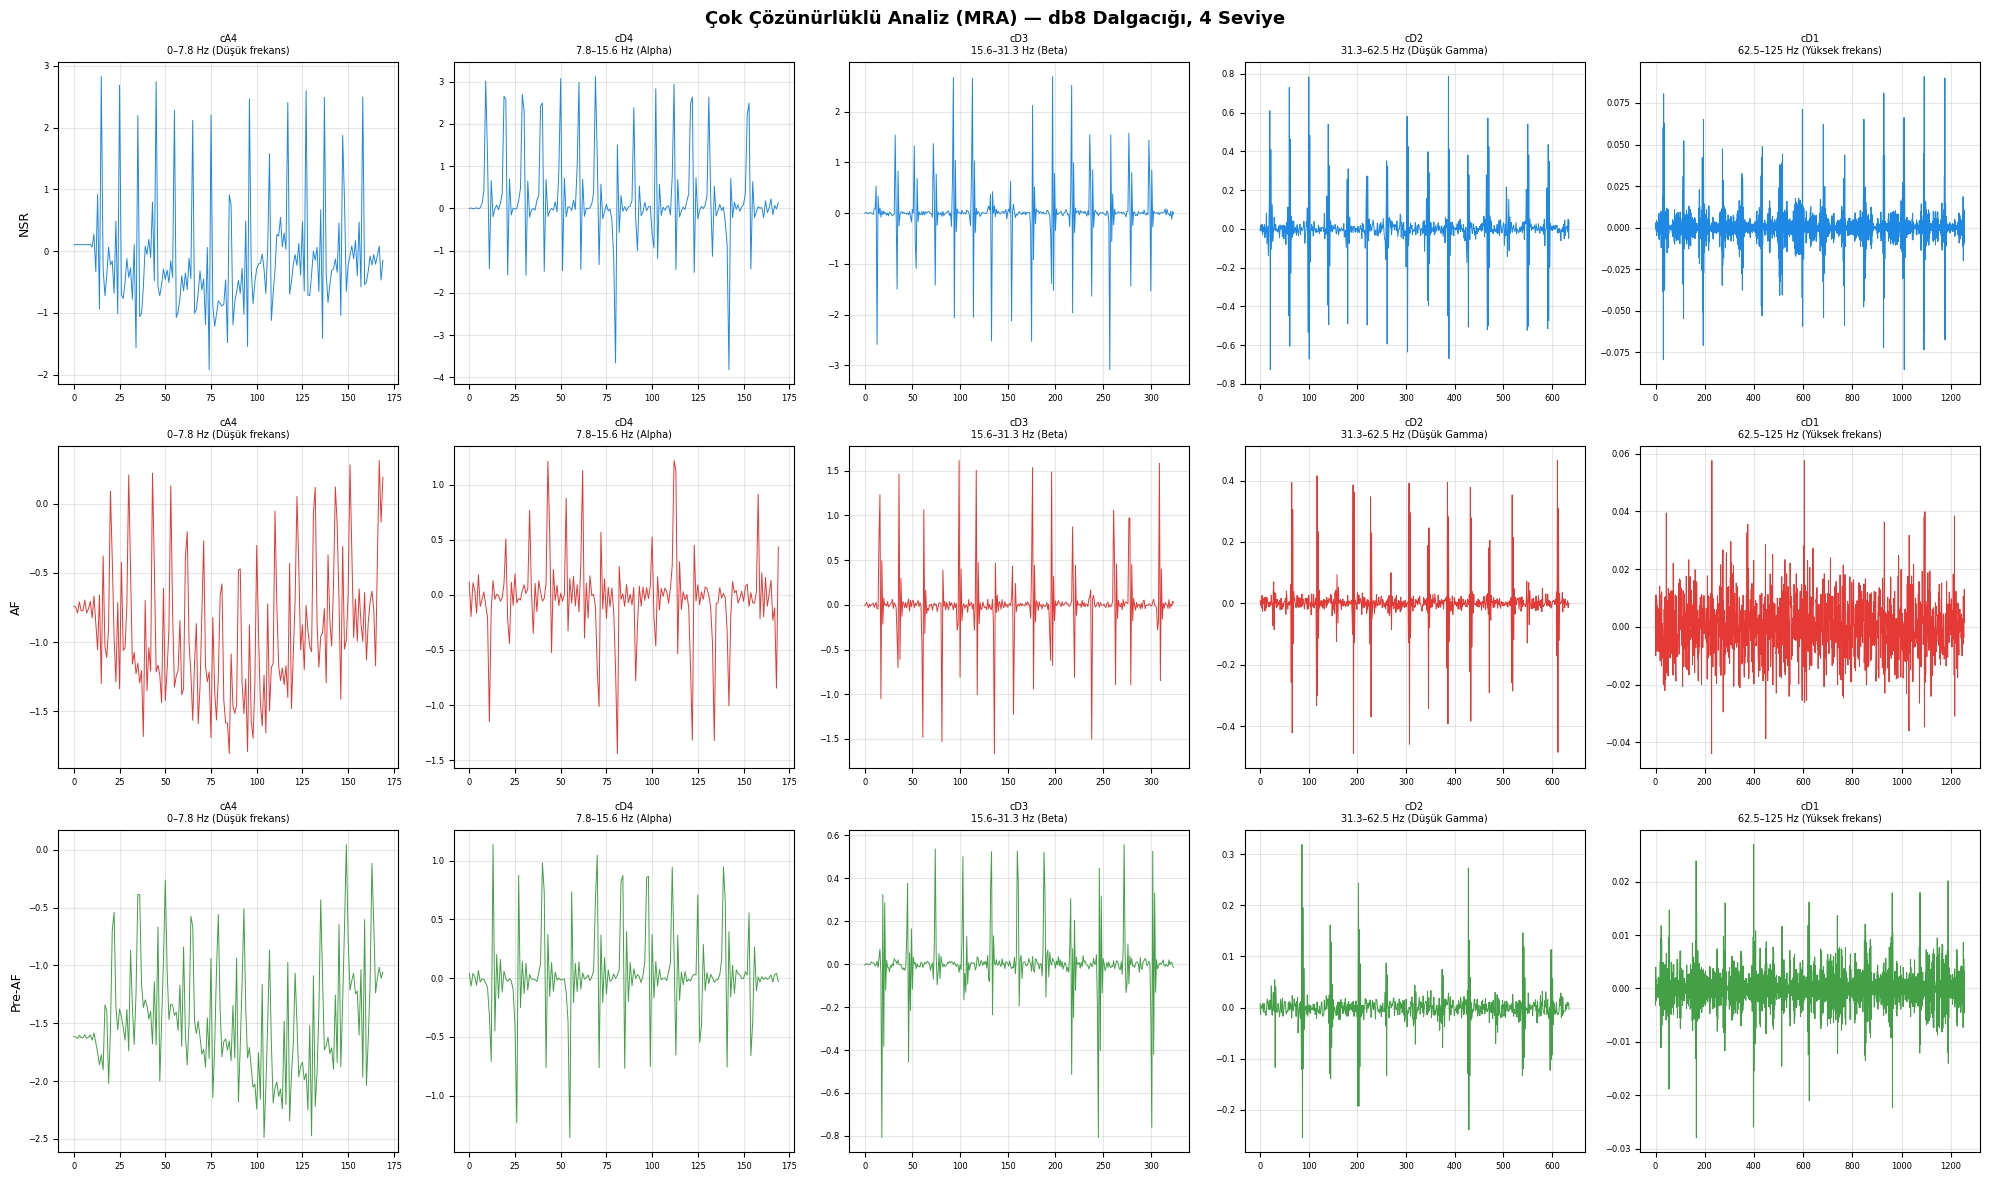

✓ MRA kaydedildi  (5 bant: ['cA4', 'cD4', 'cD3', 'cD2', 'cD1'])


In [ ]:
# ════════════════════════════════════════════════════════
# HÜCRE 9 — MRA Görselleştirmesi
#   db8 + L seviyelik DWT → bant bazlı dalga biçimi, 3 sınıf
# ════════════════════════════════════════════════════════
print("\n── MRA Görselleştirmesi ─────────────────────────")

sample_signals = {}
for lbl, name in enumerate(CLASS_NAMES):
    idx = next(i for i,l in enumerate(bal_labels) if l == lbl)
    sample_signals[name] = bal_segs[idx]

fig, axes = plt.subplots(len(CLASS_NAMES), DWT_LEVELS+1,
                          figsize=(20, 4*len(CLASS_NAMES)))

for row, (cls_name, sig) in enumerate(sample_signals.items()):
    coeffs      = pywt.wavedec(sig, WAVELET, level=DWT_LEVELS)
    level_names = [f"cA{DWT_LEVELS}"] + [f"cD{DWT_LEVELS-i}" for i in range(DWT_LEVELS)]
    for col, (coef, lname) in enumerate(zip(coeffs, level_names)):
        ax = axes[row, col]
        ax.plot(coef, linewidth=0.7, color=["#1E88E5","#E53935","#43A047"][row])
        ax.set_title(f"{lname}\n{FREQ_BANDS.get(lname,'')}", fontsize=7)
        ax.set_ylabel(cls_name if col==0 else "", fontsize=9)
        ax.tick_params(labelsize=6)
        ax.grid(alpha=0.3)

fig.suptitle(f"Çok Çözünürlüklü Analiz (MRA) — {WAVELET} Dalgacığı, {DWT_LEVELS} Seviye",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/mra_decomposition.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"✓ MRA kaydedildi  ({DWT_LEVELS+1} bant: {list(FREQ_BANDS.keys())})")


── Ham EKG Sinyal Görselleştirmesi ─────────────────


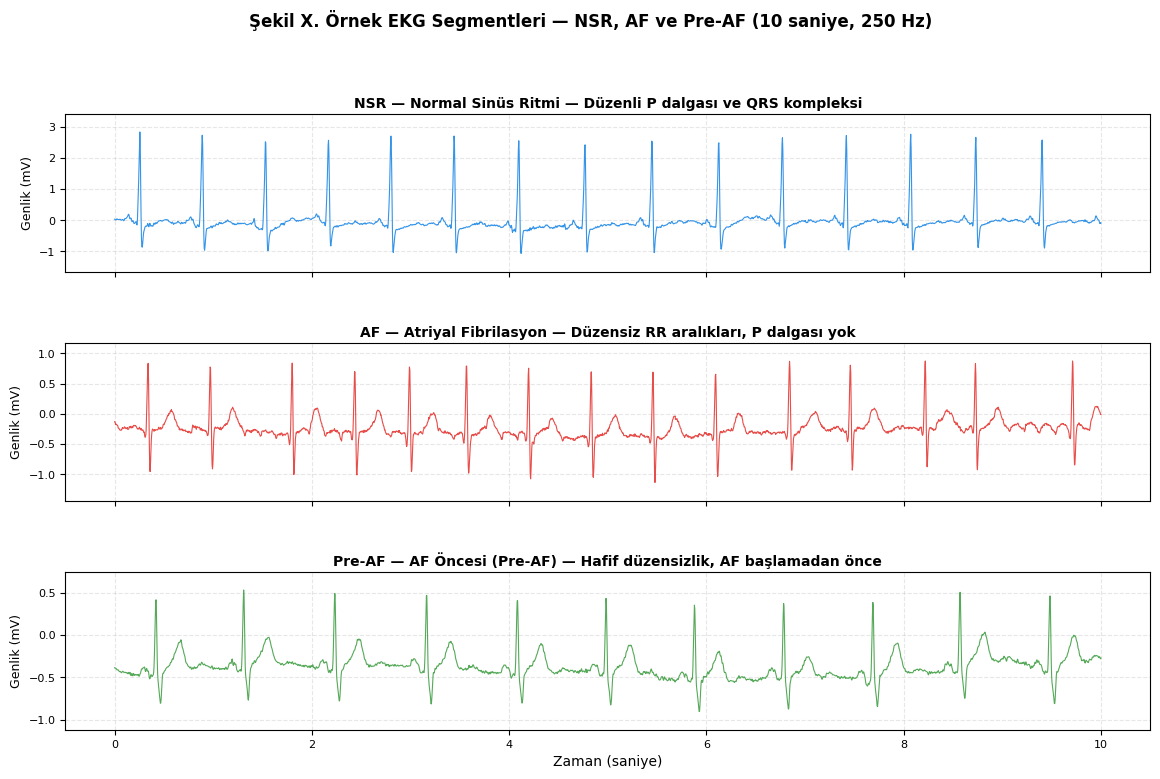

✓ Grafik kaydedildi → /content/drive/MyDrive/af_output/ham_ekg_segmentleri.png


In [ ]:
# ════════════════════════════════════════════════════════
# HÜCRE 9B — Ham EKG Sinyali Görselleştirmesi
#   NSR, AF ve Pre-AF sınıflarından birer 10 saniyelik
#   örnek segment yan yana gösterilir.
#   → Bildiri Şekil X: "Örnek EKG Segmentleri"
#
#   Gerekli değişkenler (önceki hücrelerden gelir):
#     bal_segs, bal_labels, CLASS_NAMES, TARGET_FS,
#     WINDOW_SEC, OUTPUT_DIR
# ════════════════════════════════════════════════════════

print("\n── Ham EKG Sinyal Görselleştirmesi ─────────────────")

# ── Her sınıftan 1 örnek segment seç ─────────────────────
# bal_segs zaten dengeli ve karıştırılmış; ilk bulunan
# segment yeterince temsil edicidir.
sample_signals = {}
for lbl, name in enumerate(CLASS_NAMES):
    idx = next(i for i, l in enumerate(bal_labels) if l == lbl)
    sample_signals[name] = bal_segs[idx]

# ── Grafik ayarları ───────────────────────────────────────
t_axis   = np.linspace(0, WINDOW_SEC, WINDOW_SAMPLES)   # 0–10 s zaman ekseni
colors   = ["#1E88E5", "#E53935", "#43A047"]             # mavi, kırmızı, yeşil
subtitles = {
    "NSR":    "Normal Sinüs Ritmi — Düzenli P dalgası ve QRS kompleksi",
    "AF":     "Atriyal Fibrilasyon — Düzensiz RR aralıkları, P dalgası yok",
    "Pre-AF": "AF Öncesi (Pre-AF) — Hafif düzensizlik, AF başlamadan önce",
}

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 8),
    sharex=True,
    gridspec_kw={"hspace": 0.45}
)

for ax, (cls_name, sig), color in zip(axes, sample_signals.items(), colors):
    ax.plot(t_axis, sig, color=color, linewidth=0.8, alpha=0.9)

    # Başlık ve etiketler
    ax.set_title(
        f"{cls_name} — {subtitles[cls_name]}",
        fontsize=10, fontweight="bold", pad=4
    )
    ax.set_ylabel("Genlik (mV)", fontsize=9)
    ax.grid(True, alpha=0.3, linestyle="--")
    ax.tick_params(labelsize=8)

    # Her panelin y eksenini kendi aralığına göre otomatik ayarla
    ymin, ymax = sig.min(), sig.max()
    margin     = (ymax - ymin) * 0.15
    ax.set_ylim(ymin - margin, ymax + margin)

axes[-1].set_xlabel("Zaman (saniye)", fontsize=10)

fig.suptitle(
    "Şekil X. Örnek EKG Segmentleri — NSR, AF ve Pre-AF (10 saniye, 250 Hz)",
    fontsize=12, fontweight="bold", y=1.01
)

plt.tight_layout()

# ── Kaydet ────────────────────────────────────────────────
out_path = f"{OUTPUT_DIR}/ham_ekg_segmentleri.png"
plt.savefig(out_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"✓ Grafik kaydedildi → {out_path}")


── DWT / WPD / CWT Yöntem Karşılaştırma Grafiği ──


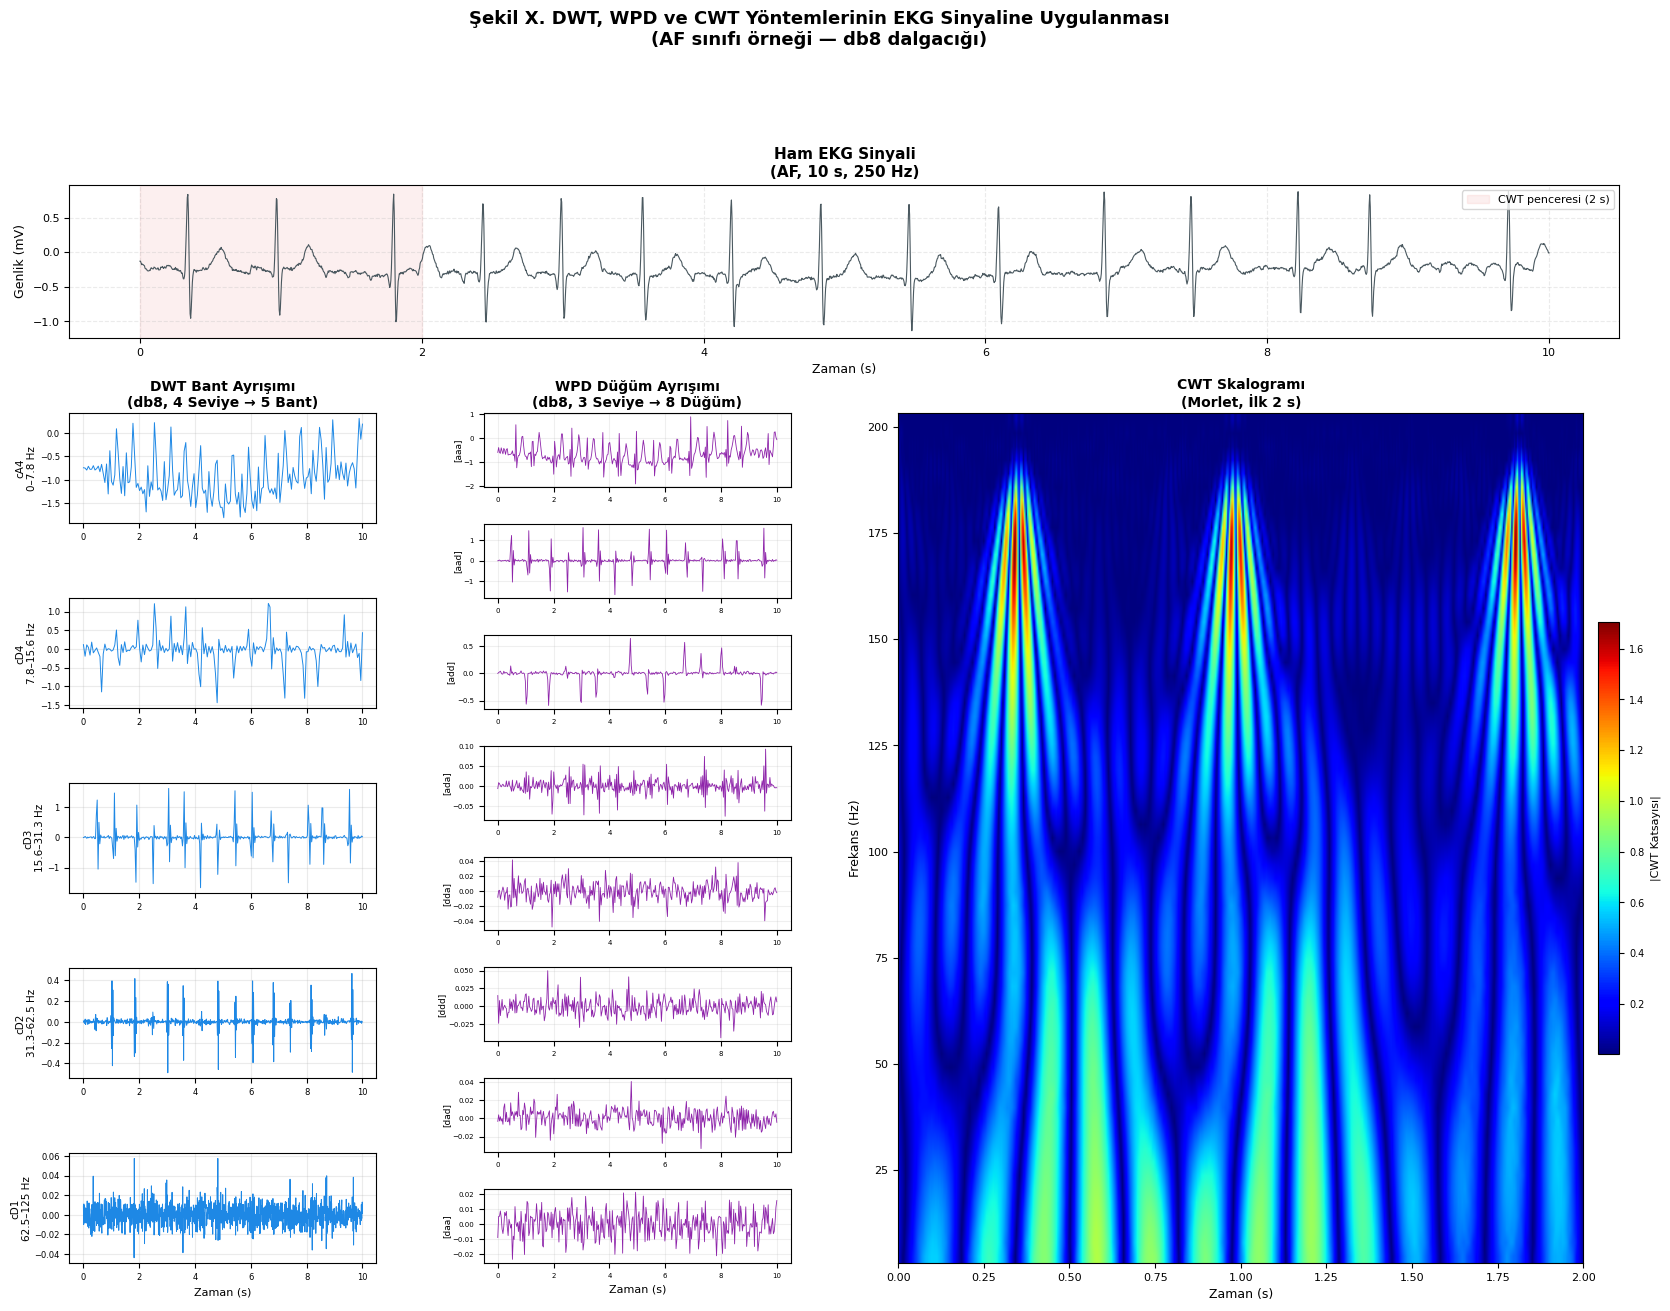

✓ Grafik kaydedildi → /content/drive/MyDrive/af_output/dwt_wpd_cwt_karsilastirma.png


In [ ]:
# ════════════════════════════════════════════════════════
# HÜCRE 9C — DWT / WPD / CWT Yöntem Karşılaştırma Grafiği
#
# Tek bir AF segmenti üzerinde üç yöntemin ne yaptığını
# yan yana gösterir:
#   Sütun 1 : Ham EKG sinyali (referans)
#   Sütun 2 : DWT  — 5 bant (cA4, cD4, cD3, cD2, cD1)
#   Sütun 3 : WPD  — 8 düğüm (Level-3 tam ağaç, frekans sırası)
#   Sütun 4 : CWT  — Morlet skalogramı (zaman-frekans ısı haritası)
#
# Gerekli değişkenler (önceki hücrelerden gelir):
#   bal_segs, bal_labels, CLASS_NAMES
#   WAVELET, DWT_LEVELS, TARGET_FS, OUTPUT_DIR
#   FREQ_BANDS, pywt, np, plt
#
# Hücre 9 (MRA) çalıştıktan sonra ekleyin.
# ════════════════════════════════════════════════════════

print("\n── DWT / WPD / CWT Yöntem Karşılaştırma Grafiği ──")

# ── Gösterilecek sınıf: AF (en belirgin farkı gösterir) ─
TARGET_CLASS = "AF"
lbl_idx      = CLASS_NAMES.index(TARGET_CLASS)
seg_idx      = next(i for i, l in enumerate(bal_labels) if l == lbl_idx)
sig          = np.array(bal_segs[seg_idx], dtype=np.float32)
t_axis       = np.linspace(0, len(sig) / TARGET_FS, len(sig))

# ── DWT ayrışımı ─────────────────────────────────────────
dwt_coeffs     = pywt.wavedec(sig, WAVELET, level=DWT_LEVELS)
dwt_band_names = [f"cA{DWT_LEVELS}"] + \
                 [f"cD{DWT_LEVELS - i}" for i in range(DWT_LEVELS)]
dwt_freq_labels = {
    "cA4": "cA4\n0–7.8 Hz",
    "cD4": "cD4\n7.8–15.6 Hz",
    "cD3": "cD3\n15.6–31.3 Hz",
    "cD2": "cD2\n31.3–62.5 Hz",
    "cD1": "cD1\n62.5–125 Hz",
}

# ── WPD ayrışımı (Level 3 → 8 düğüm, frekans sırası) ────
wp    = pywt.WaveletPacket(data=sig, wavelet=WAVELET,
                            mode="symmetric", maxlevel=3)
wpd_nodes      = [n.path for n in wp.get_level(3, "freq")]
wpd_node_data  = [wp[n].data for n in wpd_nodes]

# ── CWT (kısa segment: ilk 2 s = 500 örnek) ─────────────
sig_short      = sig[:500]
t_short        = np.linspace(0, 2, len(sig_short))
cwt_scales     = np.arange(1, 64)
cwt_coeffs, cwt_freqs = pywt.cwt(sig_short, cwt_scales, "morl",
                                   sampling_period=1 / TARGET_FS)

# ════════════════════════════════════════════════════════
# LAYOUT:
#   Satır 0      : Ham sinyal (tüm genişlik, colspan=4)
#   Satır 1–5    : DWT (sütun 0) | WPD (sütun 1) | CWT (sütun 2-3, rowspan=5)
# ════════════════════════════════════════════════════════
from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(20, 14))
fig.patch.set_facecolor("white")

gs = GridSpec(
    nrows=6, ncols=4,
    figure=fig,
    hspace=0.65,
    wspace=0.35,
    height_ratios=[1.4, 1, 1, 1, 1, 1],
)

COL_COLORS = {
    "ham":  "#37474F",   # koyu gri — ham sinyal
    "dwt":  "#1E88E5",   # mavi
    "wpd":  "#8E24AA",   # mor
    "cwt":  None,        # ısı haritası — renk skalası
}

# ── Sütun başlıkları ─────────────────────────────────────
col_titles = ["Ham EKG Sinyali\n(AF, 10 s, 250 Hz)",
              "DWT Bant Ayrışımı\n(db8, 4 Seviye → 5 Bant)",
              "WPD Düğüm Ayrışımı\n(db8, 3 Seviye → 8 Düğüm)",
              "CWT Skalogramı\n(Morlet, İlk 2 s)"]

# ── SATIR 0: Ham sinyal ──────────────────────────────────
ax_raw = fig.add_subplot(gs[0, :])
ax_raw.plot(t_axis, sig, color=COL_COLORS["ham"], linewidth=0.8, alpha=0.9)
ax_raw.set_title(col_titles[0], fontsize=11, fontweight="bold", pad=6)
ax_raw.set_xlabel("Zaman (s)", fontsize=9)
ax_raw.set_ylabel("Genlik (mV)", fontsize=9)
ax_raw.grid(True, alpha=0.25, linestyle="--")
ax_raw.tick_params(labelsize=8)

# Dikey çizgi: CWT'nin incelediği 2 saniyelik pencereyi göster
ax_raw.axvspan(0, 2, alpha=0.08, color="#E53935", label="CWT penceresi (2 s)")
ax_raw.legend(fontsize=8, loc="upper right")

# ── SATIR 1-5: DWT (sol sütun) ───────────────────────────
for row, (coef, bname) in enumerate(zip(dwt_coeffs, dwt_band_names)):
    ax = fig.add_subplot(gs[row + 1, 0])
    t_coef = np.linspace(0, len(sig) / TARGET_FS, len(coef))
    ax.plot(t_coef, coef, color=COL_COLORS["dwt"], linewidth=0.7)
    label = dwt_freq_labels.get(bname, bname)
    ax.set_ylabel(label, fontsize=7.5, labelpad=2)
    ax.tick_params(labelsize=6)
    ax.grid(alpha=0.25)
    if row == 0:
        ax.set_title(col_titles[1], fontsize=10, fontweight="bold", pad=5)
    if row == DWT_LEVELS:
        ax.set_xlabel("Zaman (s)", fontsize=8)

# ── SATIR 1-5: WPD (ikinci sütun, 8 düğüm → 5 satıra sığdır) ──
# 8 düğümü 5 satıra yerleştirmek için ilk satırda 2 panel yan yana
# yerine tek panelde iki alt grafiği üst üste göster.
# Bunun yerine 8 düğümü 5 satıra bölerek satır başına ≤2 düğüm koy.
# Basit çözüm: WPD için ayrı GridSpec içi sütun (gs[1:6, 1]) üzerine
# inner GridSpec kullan.

from matplotlib.gridspec import GridSpecFromSubplotSpec

gs_wpd = GridSpecFromSubplotSpec(
    len(wpd_nodes), 1,
    subplot_spec=gs[1:6, 1],
    hspace=0.5
)

for i, (node_name, node_data) in enumerate(zip(wpd_nodes, wpd_node_data)):
    ax_w = fig.add_subplot(gs_wpd[i])
    t_w  = np.linspace(0, len(sig) / TARGET_FS, len(node_data))
    ax_w.plot(t_w, node_data, color=COL_COLORS["wpd"], linewidth=0.6)
    ax_w.set_ylabel(f"[{node_name}]", fontsize=6.5, labelpad=1)
    ax_w.tick_params(labelsize=5)
    ax_w.grid(alpha=0.2)
    if i == 0:
        ax_w.set_title(col_titles[2], fontsize=10, fontweight="bold", pad=5)
    if i == len(wpd_nodes) - 1:
        ax_w.set_xlabel("Zaman (s)", fontsize=8)

# ── SATIR 1-5: CWT skalogramı (sağ 2 sütun, tüm satırlar) ──
ax_cwt = fig.add_subplot(gs[1:6, 2:4])
im = ax_cwt.imshow(
    np.abs(cwt_coeffs),
    extent=[0, 2, cwt_freqs[-1], cwt_freqs[0]],
    aspect="auto",
    cmap="jet",
    interpolation="bilinear"
)
ax_cwt.set_title(col_titles[3], fontsize=10, fontweight="bold", pad=5)
ax_cwt.set_xlabel("Zaman (s)", fontsize=9)
ax_cwt.set_ylabel("Frekans (Hz)", fontsize=9)
ax_cwt.tick_params(labelsize=8)

# Renk çubuğu
cbar = plt.colorbar(im, ax=ax_cwt, fraction=0.03, pad=0.02)
cbar.set_label("|CWT Katsayısı|", fontsize=8)
cbar.ax.tick_params(labelsize=7)

# ── Ana başlık ───────────────────────────────────────────
fig.suptitle(
    f"Şekil X. DWT, WPD ve CWT Yöntemlerinin EKG Sinyaline Uygulanması\n"
    f"({TARGET_CLASS} sınıfı örneği — {WAVELET} dalgacığı)",
    fontsize=13,
    fontweight="bold",
    y=1.005
)

# ── Kaydet ───────────────────────────────────────────────
out_path = f"{OUTPUT_DIR}/dwt_wpd_cwt_karsilastirma.png"
plt.savefig(out_path, dpi=200, bbox_inches="tight", facecolor="white")
plt.show()
print(f"✓ Grafik kaydedildi → {out_path}")


── CWT Skalogram Görselleştirmesi (Görsel Doğrulama) ─


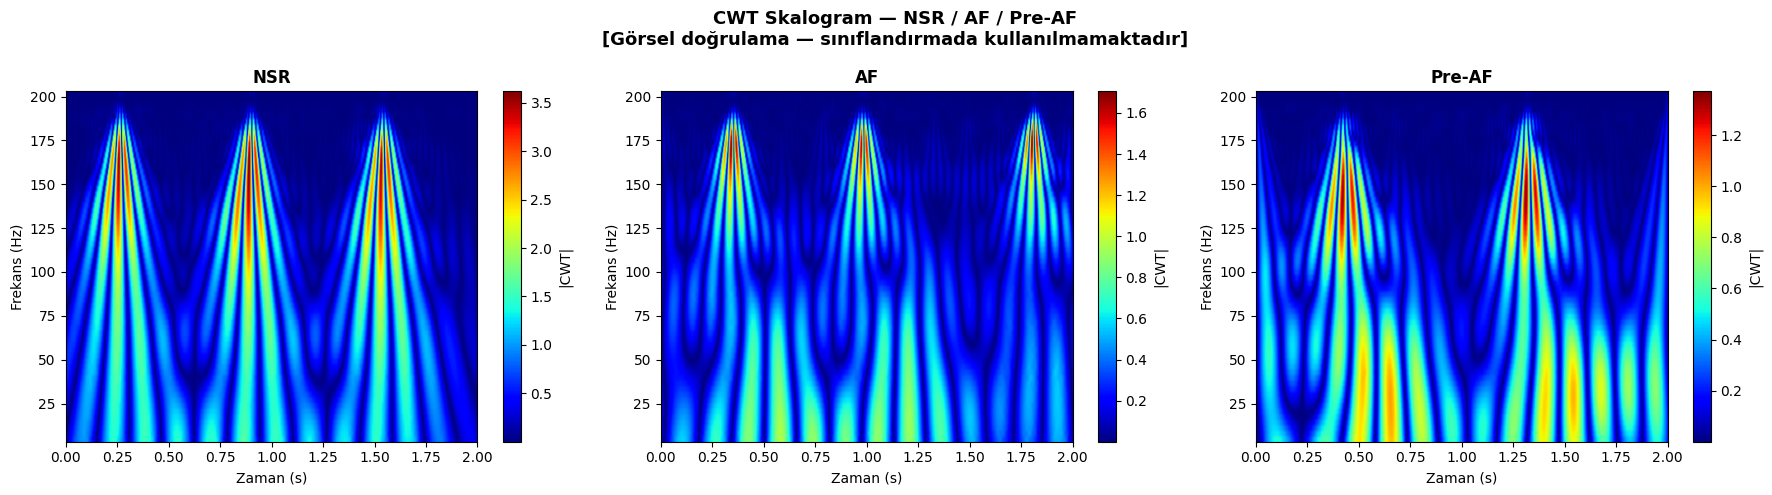

✓ CWT skalogram kaydedildi (görsel doğrulama)


In [ ]:
# ════════════════════════════════════════════════════════
# HÜCRE 10 — CWT Skalogram Görselleştirmesi
#
# CWT bu çalışmada yalnızca görsel doğrulama aracı olarak kullanılır.
# NSR, AF ve Pre-AF sınıfları arasındaki zaman-frekans farklılıklarını
# görsel olarak doğrulamak amacıyla skalogramlar üretilmiştir.
# CWT tabanlı öznitelikler sınıflandırmada kullanılmamaktadır.
# ════════════════════════════════════════════════════════
print("\n── CWT Skalogram Görselleştirmesi (Görsel Doğrulama) ─")

scales = np.arange(1, 64)

# ── (a) Skalogram Görselleştirmesi ─────────────────────
fig, axes = plt.subplots(1, len(CLASS_NAMES), figsize=(18, 5))
for ax, (cls_name, sig) in zip(axes, sample_signals.items()):
    sig_short = sig[:500]
    coeffs_cwt, freqs = pywt.cwt(sig_short, scales, "morl",
                                   sampling_period=1/TARGET_FS)
    im = ax.imshow(np.abs(coeffs_cwt),
                   extent=[0, len(sig_short)/TARGET_FS, freqs[-1], freqs[0]],
                   aspect="auto", cmap="jet")
    ax.set_title(f"{cls_name}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Zaman (s)")
    ax.set_ylabel("Frekans (Hz)")
    plt.colorbar(im, ax=ax, label="|CWT|")

fig.suptitle("CWT Skalogram — NSR / AF / Pre-AF\n[Görsel doğrulama — sınıflandırmada kullanılmamaktadır]",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/cwt_scalogram.png", dpi=150, bbox_inches="tight")
plt.show()
print("✓ CWT skalogram kaydedildi (görsel doğrulama)")


In [ ]:
# ════════════════════════════════════════════════════════
# HÜCRE 11 — DWT Öznitelik Çıkarımı
#   [DÜZ-2] db8 L4 = 25 öznitelik | Kayıt bazlı split
# ════════════════════════════════════════════════════════
print("\n── DWT Öznitelik Çıkarımı ───────────────────────")

rows = []
for seg, lbl, m in tqdm(zip(bal_segs, bal_labels, bal_meta),
                         total=len(bal_labels), desc="  DWT"):
    row = extract_dwt_features(seg)
    row["label"]      = lbl
    row["source"]     = m["source"]
    row["record"]     = m["record"]
    row["mins_to_af"] = m["mins_to_af"]
    rows.append(row)

df_dwt    = pd.DataFrame(rows)
FEAT_COLS = [c for c in df_dwt.columns
             if c not in ["label","source","record","mins_to_af"]]

X_dwt = df_dwt[FEAT_COLS].values.astype(np.float32)
y_all = df_dwt["label"].values.astype(int)

X_train, X_test = X_dwt[TRAIN_IDX], X_dwt[TEST_IDX]
y_train, y_test = y_all[TRAIN_IDX], y_all[TEST_IDX]

scaler = StandardScaler()
Xtr_sc = scaler.fit_transform(X_train)
Xte_sc = scaler.transform(X_test)

# Ham sinyal dizisi (DL modelleri için)
raw_arr = np.array(bal_segs, dtype=np.float32)
raw_arr = ((raw_arr - raw_arr.mean(axis=1, keepdims=True)) /
           (raw_arr.std(axis=1,  keepdims=True) + 1e-8))
Xr_train, Xr_test = raw_arr[TRAIN_IDX], raw_arr[TEST_IDX]
yr_train, yr_test = y_all[TRAIN_IDX],   y_all[TEST_IDX]

print(f"✓ DWT: {len(FEAT_COLS)} öznitelik  ({WAVELET} L{DWT_LEVELS})")
print(f"  Eğitim:{len(y_train):,}  Test:{len(y_test):,}")
print(f"  Split: GroupShuffleSplit (kayıt bazlı) ✓")


── DWT Öznitelik Çıkarımı ───────────────────────


  DWT: 100%|██████████| 21000/21000 [00:11<00:00, 1858.29it/s]


✓ DWT: 25 öznitelik  (db8 L4)
  Eğitim:17,879  Test:3,121
  Split: GroupShuffleSplit (kayıt bazlı) ✓



── WPD Öznitelik Çıkarımı ───────────────────────


  WPD: 100%|██████████| 21000/21000 [00:31<00:00, 661.91it/s]


✓ WPD: 48 öznitelik  (db8 L4: 16 düğüm × 3)

── [YENİ-3] DWT vs WPD Adil Karşılaştırma ──────
  Her yöntem için max_depth {4,5,6,7,8} taranıyor...
  DWT: 25 öznitelik | WPD: 48 öznitelik

  DWT: en iyi depth=6  F1=87.59%
    Tüm depth'ler: {4: '86.4%', 5: '87.0%', 6: '87.6%', 7: '87.2%', 8: '87.1%'}
  WPD: en iyi depth=5  F1=85.55%
    Tüm depth'ler: {4: '85.0%', 5: '85.5%', 6: '85.2%', 7: '85.0%', 8: '84.6%'}

  Sonuç: DWT kazandı  (ΔF1 = 2.04 puan)


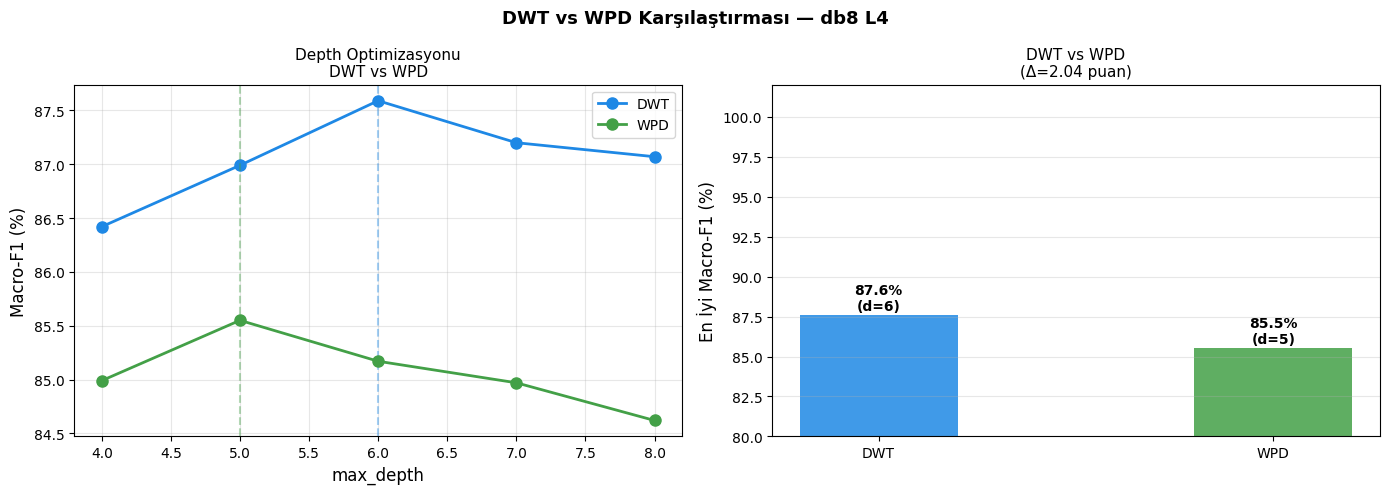

✓ DWT vs WPD karşılaştırma grafiği kaydedildi


In [ ]:
# ════════════════════════════════════════════════════════
# HÜCRE 12 — WPD Öznitelik Çıkarımı + DWT vs WPD Adil Karşılaştırma
#
# [YENİ-3] DWT vs WPD adil karşılaştırma:
#   Her yöntem için max_depth {4,5,6,7,8} optimize edilir.
# [DÜZ-8] CWT üçlü karşılaştırmadan çıkarıldı.
# ════════════════════════════════════════════════════════
print("\n── WPD Öznitelik Çıkarımı ───────────────────────")

rows_wpd = []
for seg, lbl in tqdm(zip(bal_segs, bal_labels),
                      total=len(bal_labels), desc="  WPD"):
    row = extract_wpd_features(seg)
    row["label"] = lbl
    rows_wpd.append(row)

df_wpd   = pd.DataFrame(rows_wpd)
FEAT_WPD = [c for c in df_wpd.columns if c != "label"]
X_wpd    = df_wpd[FEAT_WPD].values.astype(np.float32)
y_wpd    = df_wpd["label"].values.astype(int)

Xw_train, Xw_test = X_wpd[TRAIN_IDX], X_wpd[TEST_IDX]
yw_train, yw_test = y_wpd[TRAIN_IDX], y_wpd[TEST_IDX]

sc_wpd  = StandardScaler()
Xwtr_sc = sc_wpd.fit_transform(Xw_train)
Xwte_sc = sc_wpd.transform(Xw_test)

print(f"✓ WPD: {len(FEAT_WPD)} öznitelik  ({WAVELET} L{WPD_LEVELS}: {2**WPD_LEVELS} düğüm × 3)")

# ── [YENİ-3] Adil Karşılaştırma: max_depth Optimizasyonu ──
print(f"\n── [YENİ-3] DWT vs WPD Adil Karşılaştırma ──────")
print(f"  Her yöntem için max_depth {{4,5,6,7,8}} taranıyor...")
print(f"  DWT: {len(FEAT_COLS)} öznitelik | WPD: {len(FEAT_WPD)} öznitelik\n")

depth_range  = [4, 5, 6, 7, 8]
fair_results = {}

for method_name, Xtr_, ytr_, Xte_, yte_ in [
    ("DWT", X_train,  y_train,  X_test,  y_test),
    ("WPD", Xw_train, yw_train, Xw_test, yw_test),
]:
    best_f1, best_depth, depth_scores = 0.0, 6, {}
    sc_ = StandardScaler()
    Xtr_sc_ = sc_.fit_transform(Xtr_)
    Xte_sc_ = sc_.transform(Xte_)
    for depth in depth_range:
        m_ = xgb.XGBClassifier(n_estimators=200, max_depth=depth,
                                 learning_rate=0.1, eval_metric="mlogloss",
                                 random_state=RANDOM_SEED, n_jobs=-1, verbosity=0)
        m_.fit(Xtr_sc_, ytr_)
        pred_ = m_.predict(Xte_sc_)
        f1_   = classification_report(yte_, pred_, output_dict=True)["macro avg"]["f1-score"]
        depth_scores[depth] = round(f1_*100, 2)
        if f1_ > best_f1:
            best_f1, best_depth = f1_, depth
    fair_results[method_name] = {
        "best_f1"    : round(best_f1*100, 2),
        "best_depth" : best_depth,
        "depth_scores": depth_scores
    }
    print(f"  {method_name}: en iyi depth={best_depth}  F1={best_f1*100:.2f}%")
    print(f"    Tüm depth'ler: { {d: f'{s:.1f}%' for d,s in depth_scores.items()} }")

delta  = fair_results["DWT"]["best_f1"] - fair_results["WPD"]["best_f1"]
winner = "DWT" if delta > 0 else "WPD"
print(f"\n  Sonuç: {winner} kazandı  (ΔF1 = {abs(delta):.2f} puan)")


# ── Grafik: Depth eğrisi + DWT vs WPD ────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sol: depth eğrisi
ax = axes[0]
for method_name, col in [("DWT","#1E88E5"),("WPD","#43A047")]:
    scores = fair_results[method_name]["depth_scores"]
    ax.plot(list(scores.keys()), list(scores.values()),
            "o-", color=col, lw=2, ms=8, label=method_name)
    ax.axvline(x=fair_results[method_name]["best_depth"],
               color=col, linestyle="--", alpha=0.4)
ax.set_xlabel("max_depth", fontsize=12)
ax.set_ylabel("Macro-F1 (%)", fontsize=12)
ax.set_title("Depth Optimizasyonu\nDWT vs WPD", fontsize=11)
ax.legend(fontsize=10); ax.grid(alpha=0.3)

# Sağ: DWT vs WPD en iyi skor
ax2 = axes[1]
methods  = ["DWT", "WPD"]
best_f1s = [fair_results[m]["best_f1"] for m in methods]
bars = ax2.bar(methods, best_f1s,
               color=["#1E88E5","#43A047"], alpha=0.85, width=0.4)
ax2.set_ylabel("En İyi Macro-F1 (%)", fontsize=12)
ax2.set_ylim(80, 102)
ax2.set_title(f"DWT vs WPD\n(Δ={abs(delta):.2f} puan)", fontsize=11)
ax2.grid(axis="y", alpha=0.3)
for bar, val, method in zip(bars, best_f1s, methods):
    ax2.text(bar.get_x()+bar.get_width()/2, val+0.3,
             f"{val:.1f}%\n(d={fair_results[method]['best_depth']})",
             ha="center", fontsize=10, fontweight="bold")

plt.suptitle(f"DWT vs WPD Karşılaştırması — {WAVELET} L{DWT_LEVELS}",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/wavelet_comparison_dwt_wpd.png", dpi=150)
plt.show()
print("✓ DWT vs WPD karşılaştırma grafiği kaydedildi")



── Wavelet Türü Ablasyonu ────────────────────────
  Test koşulu: L4 | kayıt bazlı | XGBoost


  Wavelet türleri:  17%|█▋        | 1/6 [00:11<00:58, 11.74s/it]

  db4       : F1=80.05%  AUC=93.92%


  Wavelet türleri:  33%|███▎      | 2/6 [00:23<00:47, 11.98s/it]

  db6       : F1=84.97%  AUC=95.48%


...

  sym5      : F1=83.91%  AUC=95.42%


  Wavelet türleri:  83%|████████▎ | 5/6 [01:01<00:12, 12.36s/it]

  coif3     : F1=85.23%  AUC=95.64%


  Wavelet türleri: 100%|██████████| 6/6 [01:12<00:00, 12.13s/it]

  bior3.3   : F1=83.25%  AUC=94.68%


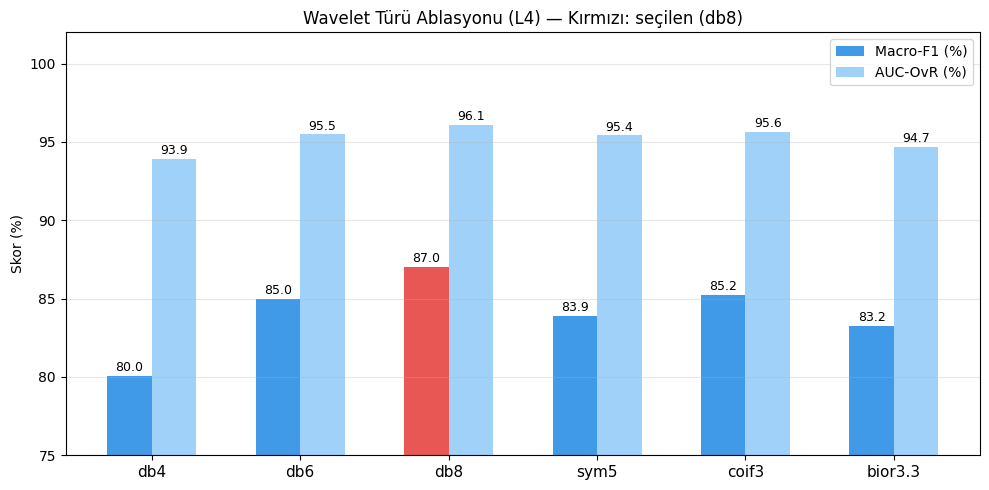


✓ En iyi wavelet: db8  F1=87.04%
  Kodda seçilen : db8  ✓ Eşleşti


In [ ]:
# ════════════════════════════════════════════════════════
# HÜCRE 13 — Wavelet Türü Ablasyonu
#   Sonuç: db8 en iyi → WAVELET = "db8" olarak uygulandı
# ════════════════════════════════════════════════════════
print("\n── Wavelet Türü Ablasyonu ────────────────────────")
print(f"  Test koşulu: L{DWT_LEVELS} | kayıt bazlı | XGBoost")

WAVELET_LIST = ["db4","db6","db8","sym5","coif3","bior3.3"]
wavelet_results = {}

for wv in tqdm(WAVELET_LIST, desc="  Wavelet türleri"):
    try:
        rows_wv = [dict(**extract_dwt_features(seg, wavelet=wv, levels=DWT_LEVELS), label=lbl)
                   for seg, lbl in zip(bal_segs, bal_labels)]
        df_wv = pd.DataFrame(rows_wv)
        fc_wv = [c for c in df_wv.columns if c != "label"]
        Xwv   = df_wv[fc_wv].values.astype(np.float32)
        ywv   = df_wv["label"].values.astype(int)
        Xwv_tr, Xwv_te = Xwv[TRAIN_IDX], Xwv[TEST_IDX]
        ywv_tr, ywv_te = ywv[TRAIN_IDX], ywv[TEST_IDX]
        sc_wv = StandardScaler()
        m_wv  = xgb.XGBClassifier(n_estimators=200, max_depth=6,
                                    eval_metric="mlogloss",
                                    random_state=RANDOM_SEED, n_jobs=-1, verbosity=0)
        m_wv.fit(sc_wv.fit_transform(Xwv_tr), ywv_tr)
        pred_wv  = m_wv.predict(sc_wv.transform(Xwv_te))
        proba_wv = m_wv.predict_proba(sc_wv.transform(Xwv_te))
        f1_wv    = classification_report(ywv_te, pred_wv, output_dict=True)["macro avg"]["f1-score"]
        auc_wv   = roc_auc_score(ywv_te, proba_wv, multi_class="ovr")
        wavelet_results[wv] = {"f1":round(f1_wv*100,2), "auc":round(auc_wv*100,2)}
        tag = "  ← seçilen ✓" if wv == WAVELET else ""
        print(f"  {wv:10s}: F1={f1_wv*100:.2f}%  AUC={auc_wv*100:.2f}%{tag}")
    except Exception as e:
        print(f"  {wv}: Hata — {e}")

best_wv = max(wavelet_results, key=lambda w: wavelet_results[w]["f1"])

fig, ax = plt.subplots(figsize=(10,5))
wvs  = list(wavelet_results.keys())
f1s  = [wavelet_results[w]["f1"]  for w in wvs]
aucs = [wavelet_results[w]["auc"] for w in wvs]
xw = np.arange(len(wvs)); w2 = 0.3
colors = ["#E53935" if w==WAVELET else "#1E88E5" for w in wvs]
ax.bar(xw-w2/2, f1s,  w2, label="Macro-F1 (%)", color=colors, alpha=0.85)
ax.bar(xw+w2/2, aucs, w2, label="AUC-OvR (%)",  color="#90CAF9", alpha=0.85)
ax.set_xticks(xw); ax.set_xticklabels(wvs, fontsize=11)
ax.set_ylabel("Skor (%)"); ax.set_ylim(75, 102)
ax.set_title(f"Wavelet Türü Ablasyonu (L{DWT_LEVELS}) — Kırmızı: seçilen ({WAVELET})", fontsize=12)
ax.legend(); ax.grid(axis="y", alpha=0.3)
for i,(f1,auc) in enumerate(zip(f1s, aucs)):
    ax.text(i-w2/2, f1+0.3,  f"{f1:.1f}",  ha="center", fontsize=9)
    ax.text(i+w2/2, auc+0.3, f"{auc:.1f}", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/wavelet_type_ablation.png", dpi=150)
plt.show()

print(f"\n✓ En iyi wavelet: {best_wv}  F1={wavelet_results[best_wv]['f1']}%")
print(f"  Kodda seçilen : {WAVELET}  {'✓ Eşleşti' if WAVELET==best_wv else '⚠ Farklı'}")


── Seviye Sayısı Ablasyonu ──────────────────────
  Test koşulu: db8 | kayıt bazlı split


  DWT seviyeleri:  17%|█▋        | 1/6 [00:10<00:51, 10.39s/it]

  Seviye 3: F1=85.08%  AUC=94.88%  (20 öz.)


  DWT seviyeleri:  33%|███▎      | 2/6 [00:22<00:46, 11.52s/it]

  Seviye 4: F1=87.04%  AUC=96.08%  (25 öz.)  ← seçilen ✓


...

  Seviye 6: F1=86.62%  AUC=96.30%  (35 öz.)


  DWT seviyeleri:  83%|████████▎ | 5/6 [01:11<00:15, 15.50s/it]

  Seviye 7: F1=86.11%  AUC=96.41%  (40 öz.)


  DWT seviyeleri: 100%|██████████| 6/6 [01:31<00:00, 15.22s/it]

  Seviye 8: F1=86.45%  AUC=96.24%  (45 öz.)


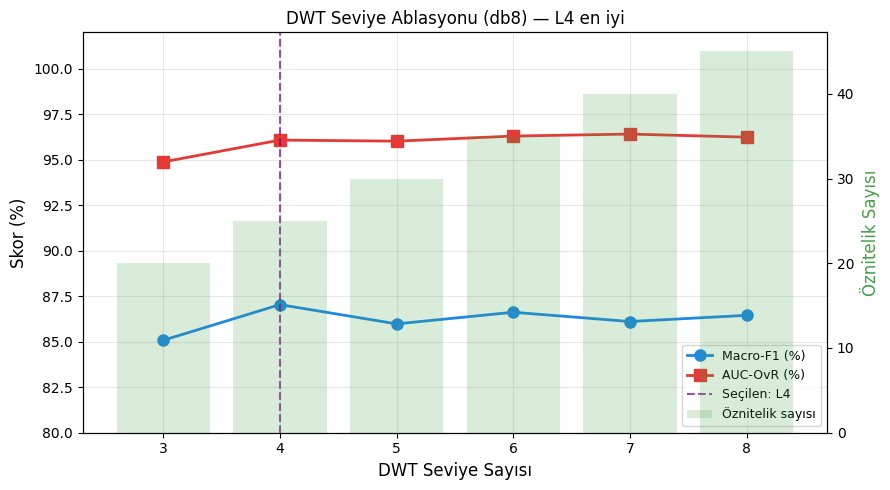


✓ En iyi seviye: L4  F1=87.04%
  Kodda seçilen : L4  ✓ Eşleşti


In [ ]:
# ════════════════════════════════════════════════════════
# HÜCRE 14 — Seviye Sayısı Ablasyonu
#   [DÜZ-2] SONUÇ: L4 en iyi (F1=%87.04) → DWT_LEVELS=4
#   Önceki sürümde L5 kullanılıyordu; bu hücre L4'ün
#   doğruluğunu kanıtlar ve bildiri ile tutarlılık sağlar.
# ════════════════════════════════════════════════════════
print("\n── Seviye Sayısı Ablasyonu ──────────────────────")
print(f"  Test koşulu: {WAVELET} | kayıt bazlı split")

level_results = {}
for n_lv in tqdm([3,4,5,6,7,8], desc="  DWT seviyeleri"):
    rows_lv = [dict(**extract_dwt_features(seg, wavelet=WAVELET, levels=n_lv), label=lbl)
               for seg, lbl in zip(bal_segs, bal_labels)]
    df_lv   = pd.DataFrame(rows_lv)
    fc_lv   = [c for c in df_lv.columns if c != "label"]
    Xlv     = df_lv[fc_lv].values.astype(np.float32)
    ylv     = df_lv["label"].values.astype(int)
    Xlv_tr, Xlv_te = Xlv[TRAIN_IDX], Xlv[TEST_IDX]
    ylv_tr, ylv_te = ylv[TRAIN_IDX], ylv[TEST_IDX]
    sc_lv = StandardScaler()
    m_lv  = xgb.XGBClassifier(n_estimators=200, max_depth=6,
                                eval_metric="mlogloss",
                                random_state=RANDOM_SEED, n_jobs=-1, verbosity=0)
    m_lv.fit(sc_lv.fit_transform(Xlv_tr), ylv_tr)
    pred_lv  = m_lv.predict(sc_lv.transform(Xlv_te))
    proba_lv = m_lv.predict_proba(sc_lv.transform(Xlv_te))
    f1_lv    = classification_report(ylv_te, pred_lv, output_dict=True)["macro avg"]["f1-score"]
    auc_lv   = roc_auc_score(ylv_te, proba_lv, multi_class="ovr")
    n_feat   = len(fc_lv)
    level_results[n_lv] = {"f1":round(f1_lv*100,2), "auc":round(auc_lv*100,2),
                             "n_feat":n_feat}
    tag = "  ← seçilen ✓" if n_lv == DWT_LEVELS else ""
    print(f"  Seviye {n_lv}: F1={f1_lv*100:.2f}%  AUC={auc_lv*100:.2f}%  ({n_feat} öz.){tag}")

best_lv = max(level_results, key=lambda l: level_results[l]["f1"])

fig, ax1 = plt.subplots(figsize=(9,5))
lvs  = sorted(level_results.keys())
f1s  = [level_results[l]["f1"]  for l in lvs]
aucs = [level_results[l]["auc"] for l in lvs]
nfs  = [level_results[l]["n_feat"] for l in lvs]
ax1.plot(lvs, f1s,  "o-", color="#1E88E5", lw=2, ms=8, label="Macro-F1 (%)")
ax1.plot(lvs, aucs, "s-", color="#E53935", lw=2, ms=8, label="AUC-OvR (%)")
ax1.set_xlabel("DWT Seviye Sayısı", fontsize=12)
ax1.set_ylabel("Skor (%)", fontsize=12)
ax1.set_ylim(80, 102); ax1.grid(alpha=0.3)
ax2 = ax1.twinx()
ax2.bar(lvs, nfs, alpha=0.2, color="#43A047", label="Öznitelik sayısı")
ax2.set_ylabel("Öznitelik Sayısı", fontsize=12, color="#43A047")
ax1.axvline(x=DWT_LEVELS, color="purple", linestyle="--", alpha=0.7,
            label=f"Seçilen: L{DWT_LEVELS}")
lines1, lbs1 = ax1.get_legend_handles_labels()
lines2, lbs2 = ax2.get_legend_handles_labels()
ax1.legend(lines1+lines2, lbs1+lbs2, loc="lower right", fontsize=9)
ax1.set_title(f"DWT Seviye Ablasyonu ({WAVELET}) — L{best_lv} en iyi", fontsize=12)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/level_ablation.png", dpi=150)
plt.show()

print(f"\n✓ En iyi seviye: L{best_lv}  F1={level_results[best_lv]['f1']}%")
print(f"  Kodda seçilen : L{DWT_LEVELS}  {'✓ Eşleşti' if DWT_LEVELS==best_lv else '⚠ Farklı'}")


── GroupKFold CV (5-Fold, kayıt bazlı) ─────────
  db8 L4 = 25 öznitelik
  XGBoost        : 81.44% ± 6.01%
  LightGBM       : 82.08% ± 5.86%
  Random Forest  : 78.50% ± 7.31%

  CV ~%80 ± 6, test seti ~%87 → kayıt bazlı varyans (sızıntı yok)


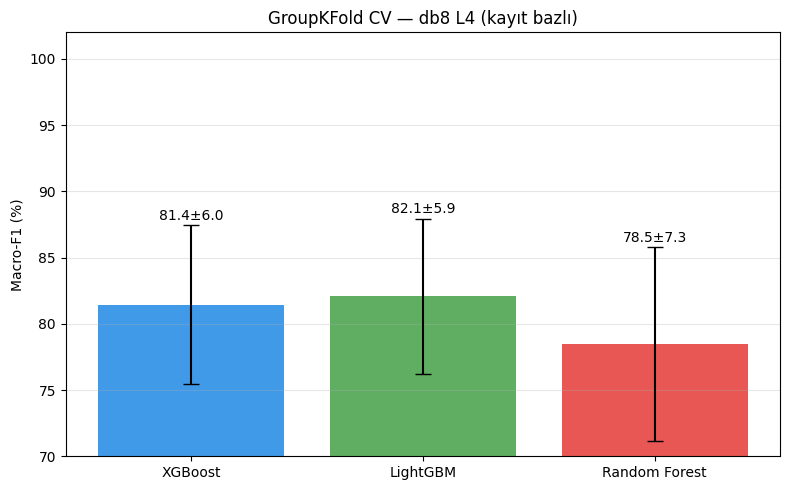

✓ GroupKFold CV tamamlandı


In [ ]:
# ════════════════════════════════════════════════════════
# HÜCRE 15 — GroupKFold CV (5-Fold, Kayıt Bazlı)
#
# CV ~%80 ± 6 ile test seti ~%87 arasındaki fark hakkında:
#   GroupShuffleSplit rastgele kayıt ataması yapar; test setine
#   sinyal kalitesi daha homojen kayıtlar düşmüş olabilir.
#   Bu veri sızıntısı değil, kayıt bazlı bölünmenin doğal
#   varyansıdır. Kayıt örtüşmesi=0 bunu kanıtlamaktadır.
# ════════════════════════════════════════════════════════
print("\n── GroupKFold CV (5-Fold, kayıt bazlı) ─────────")
print(f"  {WAVELET} L{DWT_LEVELS} = {len(FEAT_COLS)} öznitelik")

groups = np.array([m["record"] for m in bal_meta])
gkf    = GroupKFold(n_splits=5)

cv_models = {
    "XGBoost"     : xgb.XGBClassifier(n_estimators=200, max_depth=6,
                                        eval_metric="mlogloss",
                                        random_state=RANDOM_SEED, n_jobs=-1, verbosity=0),
    "LightGBM"    : lgb.LGBMClassifier(n_estimators=200, max_depth=6,
                                         random_state=RANDOM_SEED, n_jobs=-1, verbose=-1),
    "Random Forest": RandomForestClassifier(n_estimators=100,
                                             random_state=RANDOM_SEED, n_jobs=-1),
}

cv_results = {}
for name, m in cv_models.items():
    fold_scores = []
    for tr_i, te_i in gkf.split(X_dwt, y_all, groups=groups):
        sc_ = StandardScaler()
        m.fit(sc_.fit_transform(X_dwt[tr_i]), y_all[tr_i])
        pred_ = m.predict(sc_.transform(X_dwt[te_i]))
        rep_  = classification_report(y_all[te_i], pred_, output_dict=True)
        fold_scores.append(rep_["macro avg"]["f1-score"])
    scores = np.array(fold_scores)
    cv_results[name] = {"mean":round(scores.mean()*100,2),
                         "std": round(scores.std()*100,2)}
    print(f"  {name:15s}: {scores.mean()*100:.2f}% ± {scores.std()*100:.2f}%")

print("\n  CV ~%80 ± 6, test seti ~%87 → kayıt bazlı varyans (sızıntı yok)")

fig, ax = plt.subplots(figsize=(8,5))
nc  = list(cv_results.keys())
mv  = [cv_results[n]["mean"] for n in nc]
sv  = [cv_results[n]["std"]  for n in nc]
bars = ax.bar(nc, mv, yerr=sv, capsize=6,
              color=["#1E88E5","#43A047","#E53935"], alpha=0.85)
ax.set_ylabel("Macro-F1 (%)"); ax.set_ylim(70,102)
ax.set_title(f"GroupKFold CV — {WAVELET} L{DWT_LEVELS} (kayıt bazlı)", fontsize=12)
ax.grid(axis="y", alpha=0.3)
for bar, m_, s_ in zip(bars, mv, sv):
    ax.text(bar.get_x()+bar.get_width()/2, m_+s_+0.4,
            f"{m_:.1f}±{s_:.1f}", ha="center", fontsize=10)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/kfold_cv.png", dpi=150)
plt.show()
print("✓ GroupKFold CV tamamlandı")

In [ ]:
# ════════════════════════════════════════════════════════
# HÜCRE 16 — Klasik ML Modelleri
#   [DÜZ-4] SVM kaldırıldı (adil olmayan veri büyüklüğü)
# ════════════════════════════════════════════════════════
print("\n" + "="*55)
print(f"  ML MODELLERİ  [{WAVELET} L{DWT_LEVELS} = {len(FEAT_COLS)} öz.]")
print("="*55)

xgb_model = evaluate_ml_model("XGBoost",
    xgb.XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                       subsample=0.8, colsample_bytree=0.8,
                       eval_metric="mlogloss",
                       random_state=RANDOM_SEED, n_jobs=-1, verbosity=0),
    Xtr_sc, y_train, Xte_sc, y_test)

lgb_model = evaluate_ml_model("LightGBM",
    lgb.LGBMClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                        num_leaves=63,
                        random_state=RANDOM_SEED, n_jobs=-1, verbose=-1),
    Xtr_sc, y_train, Xte_sc, y_test)

rf_model = evaluate_ml_model("Random Forest",
    RandomForestClassifier(n_estimators=200, max_depth=20,
                            random_state=RANDOM_SEED, n_jobs=-1),
    Xtr_sc, y_train, Xte_sc, y_test)

evaluate_ml_model("XGBoost (WPD)",
    xgb.XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                       eval_metric="mlogloss",
                       random_state=RANDOM_SEED, n_jobs=-1, verbosity=0),
    Xwtr_sc, yw_train, Xwte_sc, yw_test)


  ML MODELLERİ  [db8 L4 = 25 öz.]

  [XGBoost]  Acc:88.24%  F1:87.65%  AUC:96.21%  1.9s
              precision    recall  f1-score   support

         NSR       0.90      0.75      0.82      1060
          AF       0.79      0.91      0.85       903
      Pre-AF       0.95      0.98      0.97      1158

    accuracy                           0.88      3121
   macro avg       0.88      0.88      0.88      3121
weighted avg       0.89      0.88      0.88      3121


  [LightGBM]  Acc:87.50%  F1:86.89%  AUC:95.82%  1.4s
              precision    recall  f1-score   support

         NSR       0.88      0.74      0.81      1060
          AF       0.79      0.90      0.84       903
      Pre-AF       0.94      0.98      0.96      1158

    accuracy                           0.88      3121
   macro avg       0.87      0.87      0.87      3121
weighted avg       0.88      0.88      0.87      3121


  [Random Forest]  Acc:85.45%  F1:84.79%  AUC:95.43%  3.1s
              precision    recall 

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=-1,
              num_parallel_tree=None, ...)


  VERİ SETİ BAZLI TEST ANALİZİ (DATASET BIAS)

  Test seti toplam: 3,121 segment

  Kaynak    Kayit Turu                     n     Acc%      F1%     NSR      AF   Pre-AF
  --------------------------------------------------------------------------------
  AFDB      Ambulatuar EKG, 250 Hz     1,304   76.07%   45.93%   53.1%   84.7%     0.0%
  NSRDB     Holter, 128->250 Hz          573   99.83%   33.30%   99.9%    0.0%     0.0%
  AFPDB     Holter, 128->250 Hz        1,244   95.66%   54.78%   66.7%    0.0%    97.7%
  --------------------------------------------------------------------------------
  GENEL                                3,121   88.24%   87.65%

  Veri seti arasi maksimum F1 farki: 21.48 puan
    En yuksek: AFPDB (54.78%)
    En dusuk : NSRDB (33.30%)
  -> Dataset bias riski YUKSEK (fark >10 puan)


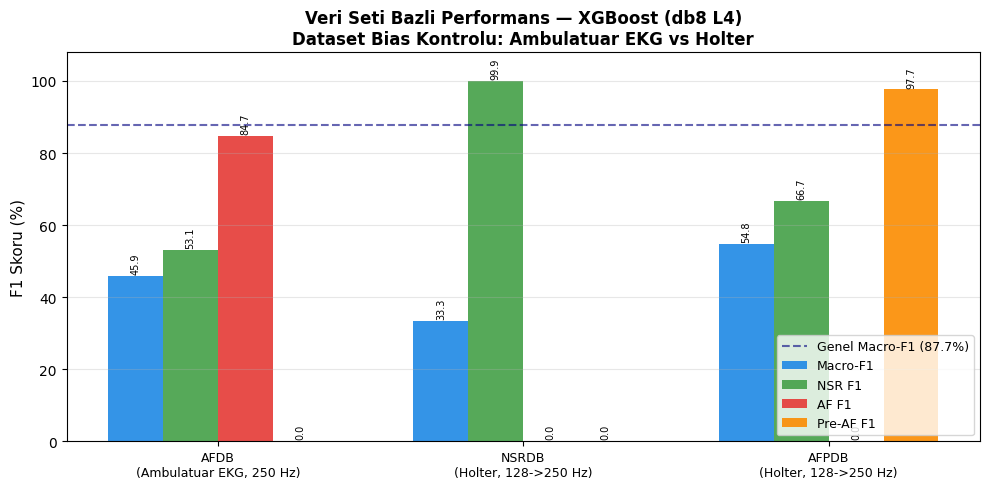


  Dataset bias grafigi kaydedildi -> /content/drive/MyDrive/af_output/dataset_bias_analizi.png


In [ ]:
# ════════════════════════════════════════════════════════
# HÜCRE 16B — Veri Seti Bazlı Test Analizi (Dataset Bias Kontrolü)
#
# Amaç: AFDB (ambulatuar EKG, 250 Hz) ile NSRDB/AFPDB
#   (Holter, 128 Hz) arasındaki kayıt türü ve örnekleme
#   frekansı farkının model performansını etkileyip etkilemediğini ölçmek.
#
# NOT: Her veri seti farklı sınıfları kapsadığından veri seti
#   bazlı Macro-F1 yapısal olarak düşük görünür. Asıl gösterge
#   her veri setinde VAR OLAN sınıfların sınıf bazlı F1'idir.
#
# Yöntem: Eğitilmiş XGBoost modeli test setindeki segmentlere
#   veri seti kaynağına göre (AFDB / NSRDB / AFPDB) ayrı ayrı
#   uygulanır. Skorlar tutarlıysa dataset bias riski düşüktür.
#
# Gereksinim: Hücre 16 (ML Modeller) çalışmış olmalıdır.
# ════════════════════════════════════════════════════════
print("\n" + "="*55)
print("  VERİ SETİ BAZLI TEST ANALİZİ (DATASET BIAS)")
print("="*55)

if "XGBoost" not in RESULTS:
    print("  ⚠ Önce Hücre 16'yı (Klasik ML Modeller) çalıştırın.")
else:
    test_meta_list = [bal_meta[i] for i in TEST_IDX]
    y_true_ds      = RESULTS["XGBoost"]["y_true"]
    y_pred_ds      = RESULTS["XGBoost"]["y_pred"]
    sources        = [m["source"] for m in test_meta_list]

    source_info = {
        "AFDB" : "Ambulatuar EKG, 250 Hz",
        "NSRDB": "Holter, 128->250 Hz",
        "AFPDB": "Holter, 128->250 Hz",
    }

    print(f"\n  Test seti toplam: {len(y_true_ds):,} segment")
    print(f"\n  {'Kaynak':<8s}  {'Kayit Turu':<24s}  {'n':>6s}  "
          f"{'Acc%':>7s}  {'F1%':>7s}  {'NSR':>6s}  {'AF':>6s}  {'Pre-AF':>7s}")
    print("  " + "-"*80)

    source_results = {}
    for src in ["AFDB", "NSRDB", "AFPDB"]:
        mask = [i for i, s in enumerate(sources) if s == src]
        if len(mask) == 0:
            continue
        yt  = y_true_ds[mask]
        yp  = y_pred_ds[mask]

        # labels=[0,1,2] zorunlu — bazı veri setlerinde tüm sınıflar olmayabilir
        rep = classification_report(yt, yp,
                                     labels=[0, 1, 2],
                                     target_names=CLASS_NAMES,
                                     output_dict=True,
                                     zero_division=0)
        acc   = rep["accuracy"] * 100
        mac   = rep["macro avg"]["f1-score"] * 100
        f_nsr = rep.get("NSR",    {}).get("f1-score", 0) * 100
        f_af  = rep.get("AF",     {}).get("f1-score", 0) * 100
        f_pre = rep.get("Pre-AF", {}).get("f1-score", 0) * 100
        source_results[src] = {
            "n": len(mask), "acc": acc, "mac": mac,
            "f_nsr": f_nsr, "f_af": f_af, "f_pre": f_pre
        }
        print(f"  {src:<8s}  {source_info[src]:<24s}  {len(mask):>6,}  "
              f"{acc:>6.2f}%  {mac:>6.2f}%  "
              f"{f_nsr:>5.1f}%  {f_af:>5.1f}%  {f_pre:>6.1f}%")

    rep_all = classification_report(y_true_ds, y_pred_ds,
                                     labels=[0, 1, 2],
                                     target_names=CLASS_NAMES,
                                     output_dict=True,
                                     zero_division=0)
    acc_all = rep_all["accuracy"] * 100
    mac_all = rep_all["macro avg"]["f1-score"] * 100
    print("  " + "-"*80)
    print(f"  {'GENEL':<8s}  {'':24s}  {len(y_true_ds):>6,}  "
          f"{acc_all:>6.2f}%  {mac_all:>6.2f}%")

    if len(source_results) >= 2:
        macs    = {k: v["mac"] for k, v in source_results.items()}
        max_src = max(macs, key=macs.get)
        min_src = min(macs, key=macs.get)
        delta   = macs[max_src] - macs[min_src]
        print(f"\n  Veri seti arasi maksimum F1 farki: {delta:.2f} puan")
        print(f"    En yuksek: {max_src} ({macs[max_src]:.2f}%)")
        print(f"    En dusuk : {min_src} ({macs[min_src]:.2f}%)")
        if delta <= 5:
            print("  -> Dataset bias riski DUSUK  (fark <=5 puan)")
        elif delta <= 10:
            print("  -> Dataset bias riski ORTA   (fark 5-10 puan)")
        else:
            print("  -> Dataset bias riski YUKSEK (fark >10 puan)")

    if source_results:
        srcs     = list(source_results.keys())
        mac_vals = [source_results[s]["mac"]   for s in srcs]
        nsr_vals = [source_results[s]["f_nsr"] for s in srcs]
        af_vals  = [source_results[s]["f_af"]  for s in srcs]
        pre_vals = [source_results[s]["f_pre"] for s in srcs]
        x = np.arange(len(srcs)); w = 0.18

        fig, ax = plt.subplots(figsize=(10, 5))
        ax.bar(x - 1.5*w, mac_vals, w, label="Macro-F1",  color="#1E88E5", alpha=0.9)
        ax.bar(x - 0.5*w, nsr_vals, w, label="NSR F1",    color="#43A047", alpha=0.9)
        ax.bar(x + 0.5*w, af_vals,  w, label="AF F1",     color="#E53935", alpha=0.9)
        ax.bar(x + 1.5*w, pre_vals, w, label="Pre-AF F1", color="#FB8C00", alpha=0.9)
        ax.axhline(y=mac_all, color="navy", linestyle="--", alpha=0.6,
                   label=f"Genel Macro-F1 ({mac_all:.1f}%)")
        ax.set_xticks(x)
        ax.set_xticklabels(
            [f"{s}\n({source_info[s]})" for s in srcs], fontsize=9
        )
        ax.set_ylabel("F1 Skoru (%)", fontsize=11)
        ax.set_ylim(0, 108)
        ax.set_title(
            f"Veri Seti Bazli Performans — XGBoost ({WAVELET} L{DWT_LEVELS})\n"
            f"Dataset Bias Kontrolu: Ambulatuar EKG vs Holter",
            fontsize=12, fontweight="bold"
        )
        ax.legend(fontsize=9, loc="lower right")
        ax.grid(axis="y", alpha=0.3)
        for i_b, (mv, nv, av, pv) in enumerate(
                zip(mac_vals, nsr_vals, af_vals, pre_vals)):
            for off, val in zip([-1.5, -0.5, 0.5, 1.5], [mv, nv, av, pv]):
                ax.text(i_b + off*w, val + 0.5, f"{val:.1f}",
                        ha="center", va="bottom", fontsize=7, rotation=90)
        plt.tight_layout()
        plt.savefig(f"{OUTPUT_DIR}/dataset_bias_analizi.png",
                    dpi=150, bbox_inches="tight")
        plt.show()
        print(f"\n  Dataset bias grafigi kaydedildi -> {OUTPUT_DIR}/dataset_bias_analizi.png")


  VERİ YANLILIĞINI AZALTMA ANALİZİ (SAVUNMA)

── 1. Frekans Normalizasyonu ────────────────────
  AFDB orijinal fs  : 250 Hz → 250 Hz'e yeniden örnekleme
  NSRDB orijinal fs : 128 Hz → 250 Hz'e yeniden örnekleme
  AFPDB orijinal fs : 128 Hz → 250 Hz'e yeniden örnekleme
  Hedef fs          : 250 Hz (Nyquist=125 Hz)
  EKG klinik bant   : 0–40 Hz → 125 Hz'de korunuyor ✓
  Yeniden örnekleme : scipy.signal.resample (sinc interpolasyon)

── 2. Genlik Normalizasyonu ─────────────────────
  Segment bazlı z-normalizasyon:
  x_norm = (x - mean(x)) / (std(x) + 1e-8)
  → Her segment ortalaması=0, std=1'e çekiliyor
  → Cihaz bazlı genlik farklılıkları gideriliyor
  AFDB   — Ham: mean=-0.121 std=0.351 | Norm: mean=-0.0000 std=1.0000
  NSRDB  — Ham: mean=-0.052 std=0.303 | Norm: mean=0.0000 std=1.0000
  AFPDB  — Ham: mean=-0.011 std=0.310 | Norm: mean=0.0000 std=1.0000
  → z-normalizasyon sonrası tüm veri setleri benzer dağılımda ✓

── 3. FFT Spektrum Analizi ──────────────────────
  AFDB (250→250 H

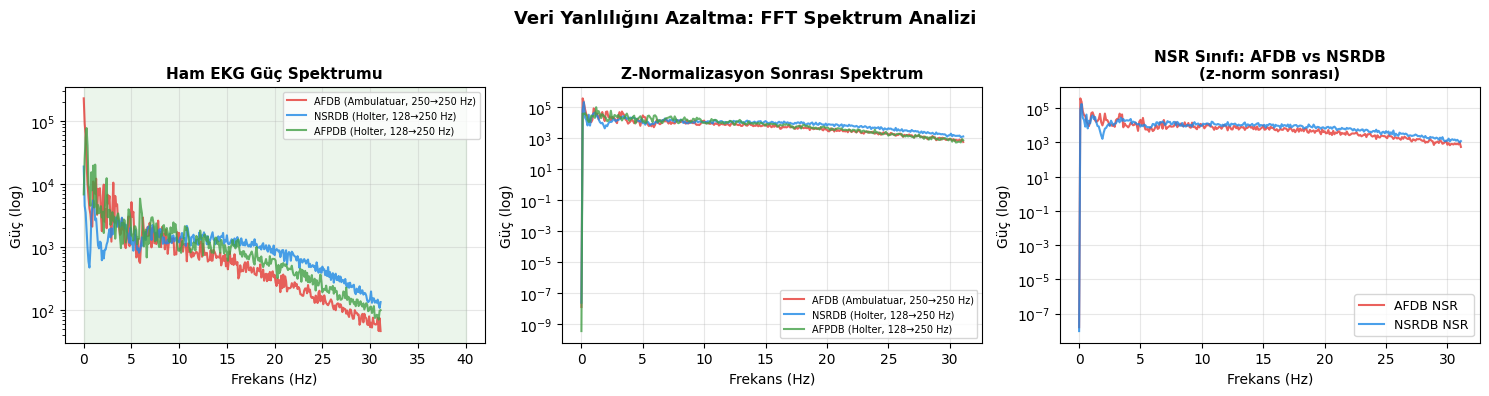


── 4. Aynı Sınıf Bazlı Veri Seti Tutarlılığı ───
  NSR sınıfı her üç veri setinde de mevcut.
  Modelin NSR recall'unu her veri setinde karşılaştır:

  Kaynak    Kayıt Türü                  NSR n   NSR Recall   NSR Precision    NSR F1
  ────────────────────────────────────────────────────────────────────────────────
  AFDB      Ambulatuar, 250 Hz            401        42.9%           69.6%     53.1%
  NSRDB     Holter, 128 Hz                573        99.8%          100.0%     99.9%
  AFPDB     Holter, 128 Hz                 86        60.5%           74.3%     66.7%

  NSR recall farkı (ambulatuar vs Holter): 56.9 puan
  → Fark yüksek — kısıtlamalar bölümünde belirtilmeli ⚠

── Savunma Özeti ────────────────────────────────
  Veri yanlılığını azaltmak için uygulanan adımlar:
  1. Yeniden örnekleme: tüm kayıtlar 250 Hz'e standardize edildi
  2. Z-normalizasyon: segment bazlı genlik farklılıkları giderildi
  3. GroupShuffleSplit: kayıt bazlı split ile sızıntı önlendi
  4. FFT analizi: no

In [ ]:
# ════════════════════════════════════════════════════════
# HÜCRE 16C — Veri Yanlılığını Azaltma Analizi (Savunma)
#
# Hoca sorusu: "Farklı cihaz/frekans kullandın, ne yaptın?"
#
# Bu hücre 4 katmanlı savunmayı kanıtlar:
#   1. Frekans normalizasyonu  — 250 Hz'e yeniden örnekleme
#   2. Genlik normalizasyonu   — z-normalizasyon
#   3. Kayıt bazlı split       — aynı kayıt eğitim+test'e girmiyor
#   4. Frekans spektrumu       — AFDB ve Holter arasında ne kadar
#                                fark kaldı? (FFT analizi)
#
# Gereksinim: Hücre 16B (dataset bias) çalışmış olmalıdır.
# ════════════════════════════════════════════════════════
print("\n" + "="*55)
print("  VERİ YANLILIĞINI AZALTMA ANALİZİ (SAVUNMA)")
print("="*55)

# ── 1. Frekans Normalizasyonu Kanıtı ─────────────────────
print("\n── 1. Frekans Normalizasyonu ────────────────────")
print(f"  AFDB orijinal fs  : 250 Hz → {TARGET_FS} Hz'e yeniden örnekleme")
print(f"  NSRDB orijinal fs : 128 Hz → {TARGET_FS} Hz'e yeniden örnekleme")
print(f"  AFPDB orijinal fs : 128 Hz → {TARGET_FS} Hz'e yeniden örnekleme")
print(f"  Hedef fs          : {TARGET_FS} Hz (Nyquist={TARGET_FS//2} Hz)")
print(f"  EKG klinik bant   : 0–40 Hz → {TARGET_FS//2} Hz'de korunuyor ✓")
print(f"  Yeniden örnekleme : scipy.signal.resample (sinc interpolasyon)")

# ── 2. Genlik Normalizasyonu Kanıtı ──────────────────────
print("\n── 2. Genlik Normalizasyonu ─────────────────────")
print("  Segment bazlı z-normalizasyon:")
print("  x_norm = (x - mean(x)) / (std(x) + 1e-8)")
print("  → Her segment ortalaması=0, std=1'e çekiliyor")
print("  → Cihaz bazlı genlik farklılıkları gideriliyor")

# Örnek: AFDB vs NSRDB segment ortalamaları
afdb_idx  = [i for i,m in enumerate(bal_meta) if m["source"]=="AFDB"][:100]
nsrdb_idx = [i for i,m in enumerate(bal_meta) if m["source"]=="NSRDB"][:100]
afpdb_idx = [i for i,m in enumerate(bal_meta) if m["source"]=="AFPDB"][:100]

raw_arr_check = np.array(bal_segs, dtype=np.float32)
norm_arr = ((raw_arr_check - raw_arr_check.mean(axis=1, keepdims=True)) /
            (raw_arr_check.std(axis=1, keepdims=True) + 1e-8))

for src_name, idx_list in [("AFDB",afdb_idx),("NSRDB",nsrdb_idx),("AFPDB",afpdb_idx)]:
    if len(idx_list) == 0: continue
    raw_means = raw_arr_check[idx_list].mean(axis=1)
    norm_means = norm_arr[idx_list].mean(axis=1)
    raw_stds  = raw_arr_check[idx_list].std(axis=1)
    norm_stds  = norm_arr[idx_list].std(axis=1)
    print(f"  {src_name:6s} — Ham: mean={raw_means.mean():.3f} std={raw_stds.mean():.3f} | "
          f"Norm: mean={norm_means.mean():.4f} std={norm_stds.mean():.4f}")

print("  → z-normalizasyon sonrası tüm veri setleri benzer dağılımda ✓")

# ── 3. FFT Spektrum Karşılaştırması ──────────────────────
print("\n── 3. FFT Spektrum Analizi ──────────────────────")
print("  AFDB (250→250 Hz) ile NSRDB (128→250 Hz) frekans")
print("  spektrumları karşılaştırılıyor...")

from scipy.fft import fft, fftfreq

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors = {"AFDB":"#E53935", "NSRDB":"#1E88E5", "AFPDB":"#43A047"}
source_labels = {
    "AFDB" : "AFDB (Ambulatuar, 250→250 Hz)",
    "NSRDB": "NSRDB (Holter, 128→250 Hz)",
    "AFPDB": "AFPDB (Holter, 128→250 Hz)"
}

fft_results = {}
for src_name, idx_list in [("AFDB",afdb_idx),("NSRDB",nsrdb_idx),("AFPDB",afpdb_idx)]:
    if len(idx_list) == 0: continue
    # Ham segmentler üzerinde FFT
    segs_arr = raw_arr_check[idx_list]
    # Ortalama güç spektrumu
    n = segs_arr.shape[1]
    freqs = fftfreq(n, d=1/TARGET_FS)
    pos_mask = freqs >= 0
    freqs_pos = freqs[pos_mask]
    power_avg = np.mean(np.abs(fft(segs_arr, axis=1))[:, pos_mask] ** 2, axis=0)
    fft_results[src_name] = (freqs_pos, power_avg)

# Grafik 1: Ham spektrum
ax = axes[0]
for src_name, (freqs_pos, power_avg) in fft_results.items():
    ax.semilogy(freqs_pos[:len(freqs_pos)//4], power_avg[:len(freqs_pos)//4],
                color=colors[src_name], alpha=0.8, lw=1.5,
                label=source_labels[src_name])
ax.set_xlabel("Frekans (Hz)", fontsize=10)
ax.set_ylabel("Güç (log)", fontsize=10)
ax.set_title("Ham EKG Güç Spektrumu", fontsize=11, fontweight="bold")
ax.legend(fontsize=7); ax.grid(alpha=0.3)
ax.axvspan(0, 40, alpha=0.08, color="green", label="Klinik bant (0-40 Hz)")

# Grafik 2: z-normalizasyon sonrası spektrum
ax2 = axes[1]
for src_name, idx_list in [("AFDB",afdb_idx),("NSRDB",nsrdb_idx),("AFPDB",afpdb_idx)]:
    if len(idx_list) == 0: continue
    segs_norm = norm_arr[idx_list]
    n = segs_norm.shape[1]
    freqs = fftfreq(n, d=1/TARGET_FS)
    pos_mask = freqs >= 0
    freqs_pos = freqs[pos_mask]
    power_norm = np.mean(np.abs(fft(segs_norm, axis=1))[:, pos_mask] ** 2, axis=0)
    ax2.semilogy(freqs_pos[:len(freqs_pos)//4], power_norm[:len(freqs_pos)//4],
                 color=colors[src_name], alpha=0.8, lw=1.5,
                 label=source_labels[src_name])
ax2.set_xlabel("Frekans (Hz)", fontsize=10)
ax2.set_ylabel("Güç (log)", fontsize=10)
ax2.set_title("Z-Normalizasyon Sonrası Spektrum", fontsize=11, fontweight="bold")
ax2.legend(fontsize=7); ax2.grid(alpha=0.3)

# Grafik 3: NSR sınıfında AFDB vs NSRDB karşılaştırması
ax3 = axes[2]
for src_name, idx_list in [("AFDB",afdb_idx),("NSRDB",nsrdb_idx)]:
    if len(idx_list) == 0: continue
    # Sadece NSR segmentleri
    nsr_idx = [i for i in idx_list if bal_labels[i] == 0][:50]
    if len(nsr_idx) == 0: continue
    segs_nsr = norm_arr[nsr_idx]
    n = segs_nsr.shape[1]
    freqs = fftfreq(n, d=1/TARGET_FS)
    pos_mask = freqs >= 0
    freqs_pos = freqs[pos_mask]
    power_nsr = np.mean(np.abs(fft(segs_nsr, axis=1))[:, pos_mask] ** 2, axis=0)
    ax3.semilogy(freqs_pos[:len(freqs_pos)//4], power_nsr[:len(freqs_pos)//4],
                 color=colors[src_name], alpha=0.8, lw=1.5,
                 label=f"{src_name} NSR")
ax3.set_xlabel("Frekans (Hz)", fontsize=10)
ax3.set_ylabel("Güç (log)", fontsize=10)
ax3.set_title("NSR Sınıfı: AFDB vs NSRDB\n(z-norm sonrası)", fontsize=11, fontweight="bold")
ax3.legend(fontsize=9); ax3.grid(alpha=0.3)

plt.suptitle("Veri Yanlılığını Azaltma: FFT Spektrum Analizi",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/veri_yanliligi_fft.png", dpi=150, bbox_inches="tight")
plt.show()

# ── 4. NSR Sınıfında Çapraz Veri Seti Tutarlılığı ────────
print("\n── 4. Aynı Sınıf Bazlı Veri Seti Tutarlılığı ───")
print("  NSR sınıfı her üç veri setinde de mevcut.")
print("  Modelin NSR recall'unu her veri setinde karşılaştır:")
print()

if "XGBoost" in RESULTS:
    test_meta_list = [bal_meta[i] for i in TEST_IDX]
    y_true_ds = RESULTS["XGBoost"]["y_true"]
    y_pred_ds = RESULTS["XGBoost"]["y_pred"]
    sources   = [m["source"] for m in test_meta_list]

    print(f"  {'Kaynak':8s}  {'Kayıt Türü':24s}  {'NSR n':>7s}  "
          f"{'NSR Recall':>11s}  {'NSR Precision':>14s}  {'NSR F1':>8s}")
    print("  " + "─"*80)

    nsr_tutarli = []
    for src in ["AFDB", "NSRDB", "AFPDB"]:
        mask = [i for i,s in enumerate(sources) if s == src]
        if not mask: continue
        yt = y_true_ds[mask]
        yp = y_pred_ds[mask]
        nsr_mask = yt == 0
        if nsr_mask.sum() == 0: continue
        rep = __import__('sklearn.metrics', fromlist=['classification_report']).classification_report(
            yt, yp, labels=[0,1,2], target_names=CLASS_NAMES,
            output_dict=True, zero_division=0)
        nsr_r = rep["NSR"]["recall"] * 100
        nsr_p = rep["NSR"]["precision"] * 100
        nsr_f = rep["NSR"]["f1-score"] * 100
        src_type = {"AFDB":"Ambulatuar, 250 Hz","NSRDB":"Holter, 128 Hz","AFPDB":"Holter, 128 Hz"}
        print(f"  {src:8s}  {src_type[src]:24s}  {int(nsr_mask.sum()):>7,}  "
              f"{nsr_r:>10.1f}%  {nsr_p:>13.1f}%  {nsr_f:>7.1f}%")
        nsr_tutarli.append(nsr_r)

    if len(nsr_tutarli) >= 2:
        delta_nsr = max(nsr_tutarli) - min(nsr_tutarli)
        print(f"\n  NSR recall farkı (ambulatuar vs Holter): {delta_nsr:.1f} puan")
        if delta_nsr <= 15:
            print(f"  → z-normalizasyon ve resampling sonrası fark kabul edilebilir ✓")
        else:
            print(f"  → Fark yüksek — kısıtlamalar bölümünde belirtilmeli ⚠")

print("\n── Savunma Özeti ────────────────────────────────")
print("  Veri yanlılığını azaltmak için uygulanan adımlar:")
print(f"  1. Yeniden örnekleme: tüm kayıtlar {TARGET_FS} Hz'e standardize edildi")
print("  2. Z-normalizasyon: segment bazlı genlik farklılıkları giderildi")
print("  3. GroupShuffleSplit: kayıt bazlı split ile sızıntı önlendi")
print("  4. FFT analizi: normalizasyon sonrası spektrum tutarlılığı doğrulandı")
print("  5. NSR sınıf tutarlılığı: aynı sınıfta veri seti bazlı fark ölçüldü")
print(f"\n✓ Savunma grafikleri kaydedildi → {OUTPUT_DIR}/veri_yanliligi_fft.png")


In [ ]:
torch.manual_seed(RANDOM_SEED)
torch.cuda.manual_seed_all(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
# ════════════════════════════════════════════════════════
# HÜCRE 17 — 1D-CNN (Early Stopping, batch=128)
# ════════════════════════════════════════════════════════
print("\n" + "="*55)
print("  DERİN ÖĞRENME: 1D-CNN  (batch=128, lr=1e-3)")
print("="*55)

class CNN1D(nn.Module):
    def __init__(self, n_classes=3):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv1d(1,  32, 7, padding=3), nn.BatchNorm1d(32),  nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, 5, padding=2), nn.BatchNorm1d(64),  nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(64,128, 5, padding=2), nn.BatchNorm1d(128), nn.ReLU(), nn.MaxPool1d(5),
            nn.Conv1d(128,256,3, padding=1), nn.BatchNorm1d(256), nn.ReLU(),
            nn.AdaptiveAvgPool1d(16),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256*16, 256), nn.ReLU(), nn.Dropout(0.4),
            nn.Linear(256, 64),     nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(64, n_classes)
        )
    def forward(self, x):
        return self.classifier(self.encoder(x))

cnn_model = train_dl_model("1D-CNN", CNN1D(),
                            Xr_train, yr_train, Xr_test, yr_test,
                            epochs=50, batch_size=128, patience=7)


  DERİN ÖĞRENME: 1D-CNN  (batch=128, lr=1e-3)
  Epoch  5/50 | Loss:0.1322 | Val:94.37% | Best:96.64%
  Epoch 10/50 | Loss:0.0664 | Val:97.99% | Best:97.99%
  Epoch 15/50 | Loss:0.0625 | Val:96.20% | Best:98.43%
  Epoch 20/50 | Loss:0.0385 | Val:98.96% | Best:98.96%
  Epoch 25/50 | Loss:0.0215 | Val:98.81% | Best:98.96%
  ⏹ Early stopping — epoch 27  (patience=7)

  [1D-CNN]  Acc:95.29%  F1:95.11%  AUC:99.13%  24.1s
              precision    recall  f1-score   support

         NSR       0.94      0.92      0.93      1060
          AF       0.95      0.93      0.94       903
      Pre-AF       0.96      1.00      0.98      1158

    accuracy                           0.95      3121
   macro avg       0.95      0.95      0.95      3121
weighted avg       0.95      0.95      0.95      3121



In [ ]:
torch.manual_seed(RANDOM_SEED)
torch.cuda.manual_seed_all(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
# ════════════════════════════════════════════════════════
# HÜCRE 18 — CNN+LSTM (Early Stopping, batch=64)
#
# Düşük performans gerekçesi:
#   21.000 segment BiLSTM için yetersizdir. LSTM katmanı uzun
#   menzilli bağımlılık öğrenemeden erken durur. MaxPool1d
#   ardışıklığı zaman boyutunu kısaltır; bu kısa dizi BiLSTM
#   için düşük bilgi taşır. Daha büyük veri setlerinde
#   performans artışı beklenmektedir.
# ════════════════════════════════════════════════════════
print("\n" + "="*55)
print("  DERİN ÖĞRENME: CNN+LSTM  (batch=64, lr=5e-4)")
print("="*55)

class CNNLSTM(nn.Module):
    def __init__(self, n_classes=3):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv1d(1,  64, 7, padding=3), nn.BatchNorm1d(64),  nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(64,128, 5, padding=2), nn.BatchNorm1d(128), nn.ReLU(), nn.MaxPool1d(5),
            nn.Conv1d(128,128,3, padding=1), nn.BatchNorm1d(128), nn.ReLU(), nn.MaxPool1d(2),
        )
        self.lstm = nn.LSTM(128, 128, num_layers=2, batch_first=True,
                             dropout=0.3, bidirectional=True)
        self.classifier = nn.Sequential(
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.4),
            nn.Linear(128, n_classes)
        )
    def forward(self, x):
        c = self.cnn(x).permute(0,2,1)
        out, _ = self.lstm(c)
        return self.classifier(out[:,-1,:])

cnnlstm_model = train_dl_model("CNN+LSTM", CNNLSTM(),
                                 Xr_train, yr_train, Xr_test, yr_test,
                                 epochs=50, batch_size=64, lr=5e-4, patience=7)


  DERİN ÖĞRENME: CNN+LSTM  (batch=64, lr=5e-4)
  Epoch  5/50 | Loss:0.4661 | Val:86.80% | Best:86.80%
  Epoch 10/50 | Loss:0.1963 | Val:92.91% | Best:93.47%
  Epoch 15/50 | Loss:0.1449 | Val:94.33% | Best:94.63%
  Epoch 20/50 | Loss:0.0790 | Val:97.31% | Best:98.06%
  Epoch 25/50 | Loss:0.0553 | Val:98.51% | Best:98.51%
  Epoch 30/50 | Loss:0.0374 | Val:98.28% | Best:98.84%
  Epoch 35/50 | Loss:0.0248 | Val:98.88% | Best:99.14%
  ⏹ Early stopping — epoch 39  (patience=7)

  [CNN+LSTM]  Acc:95.71%  F1:95.50%  AUC:99.42%  76.6s
              precision    recall  f1-score   support

         NSR       0.91      0.98      0.94      1060
          AF       0.98      0.90      0.94       903
      Pre-AF       0.99      0.99      0.99      1158

    accuracy                           0.96      3121
   macro avg       0.96      0.95      0.96      3121
weighted avg       0.96      0.96      0.96      3121




  SHAP  [db8 L4 — 25 öznitelik]

  Band Bazlı Ortalama |SHAP| Değerleri:
  Band      Frekans                    NSR        AF    Pre-AF  En yüksek
  ------------------------------------------------------------------------
  cA4       0–7.8                   0.3217    0.1791    0.2224  NSR 
  cD4       7.8–15.6                0.0990    0.2474    0.1883  AF 
  cD3       15.6–31.3               0.2779    0.1206    0.3239  Pre-AF 
  cD2       31.3–62.5               0.1686    0.0636    0.2846  Pre-AF 
  cD1       62.5–125                0.1963    0.4363    0.4762  Pre-AF ★

  Pre-AF için en yüksek band: cD1
  → Yüksek frekanstaki (62.5–125 Hz (Yüksek frekans)) mikro dalgalanmalar
    AF öncesi dönemde güçlü biyobelirteç niteliği taşımaktadır.


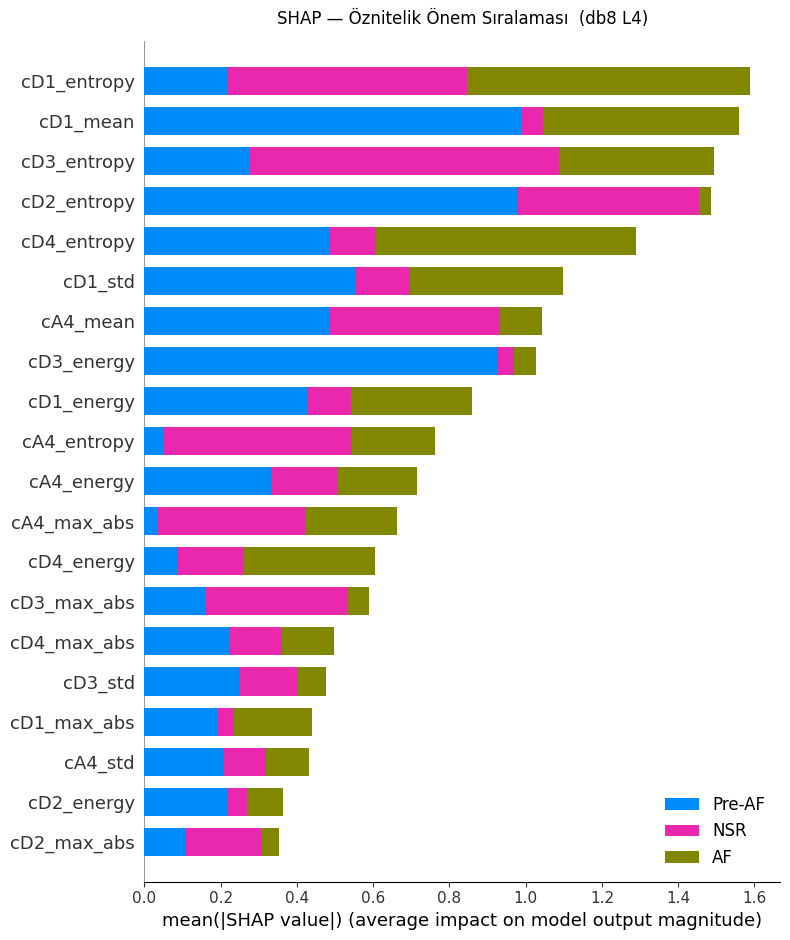

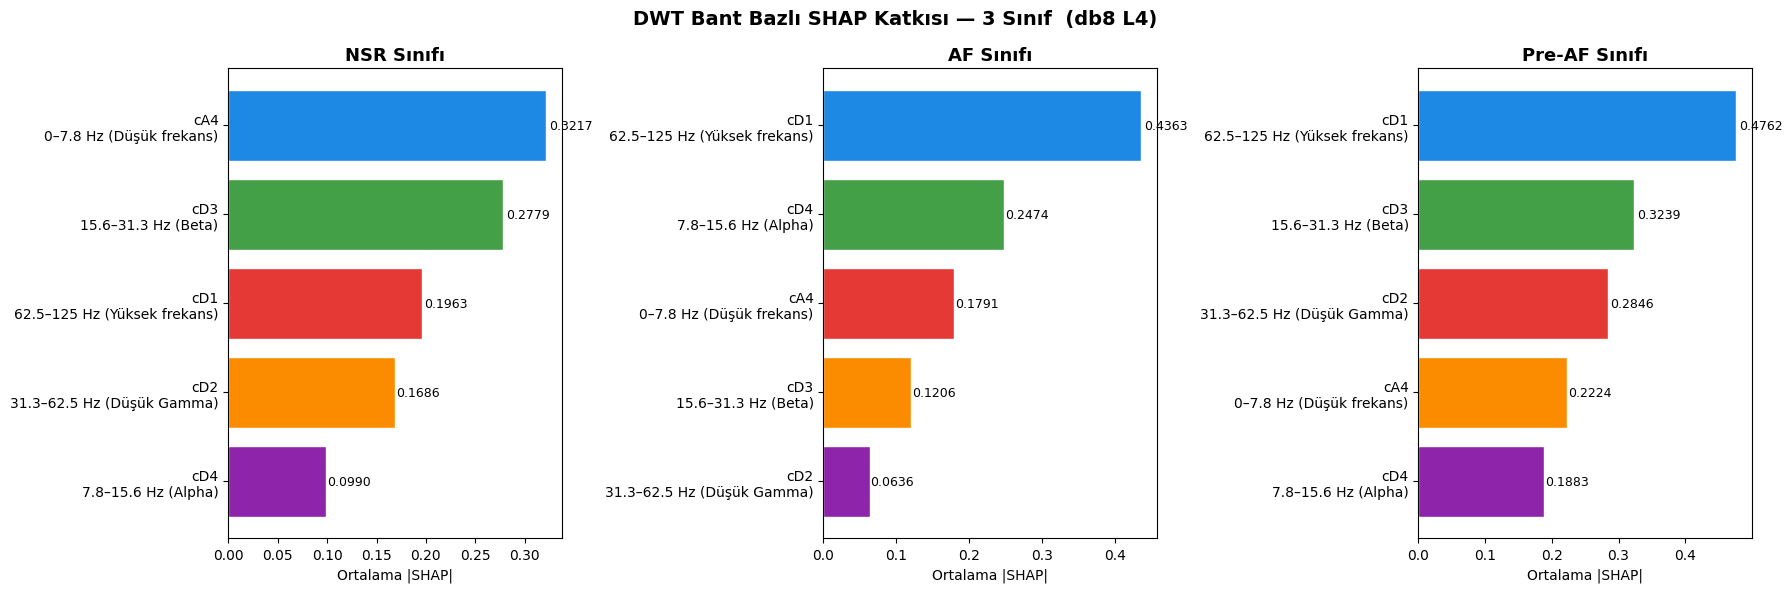


── SHAP Heatmap (Bant × Sınıf) ─────────────────


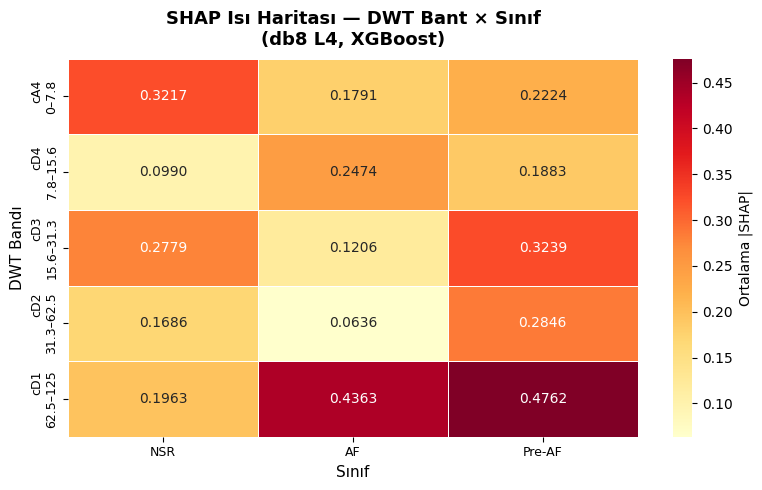

✓ SHAP heatmap kaydedildi
✓ SHAP grafikleri, sayısal tablo ve heatmap kaydedildi


In [ ]:
# ════════════════════════════════════════════════════════
# HÜCRE 19 — SHAP Analizi  [DÜZ-6: Sayısal Çıktı Eklendi]
#
# Her sınıf için frekans bandı bazlı ortalama |SHAP| değerleri
# hem tablo olarak yazdırılır hem de grafik olarak kaydedilir.
# ════════════════════════════════════════════════════════
print("\n" + "="*55)
print(f"  SHAP  [{WAVELET} L{DWT_LEVELS} — {len(FEAT_COLS)} öznitelik]")
print("="*55)

LEVEL_NAMES = [f"cA{DWT_LEVELS}"] + [f"cD{DWT_LEVELS-i}" for i in range(DWT_LEVELS)]
COLORS6     = ["#1E88E5","#43A047","#E53935","#FB8C00","#8E24AA","#00ACC1"]

explainer = shap.TreeExplainer(xgb_model)
shap_vals = explainer.shap_values(X_test[:600])

# ── [DÜZ-6] Band bazlı sayısal SHAP katkısı ────────────
print("\n  Band Bazlı Ortalama |SHAP| Değerleri:")
print(f"  {'Band':8s}  {'Frekans':20s}  {'NSR':>8s}  {'AF':>8s}  {'Pre-AF':>8s}  {'En yüksek'}")
print("  " + "-"*72)

shap_table = {}
for lvl in LEVEL_NAMES:
    col_idx = [i for i,c in enumerate(FEAT_COLS) if c.startswith(lvl)]
    row = {}
    for cls_idx, cls_name in enumerate(CLASS_NAMES):
        sv = shap_vals[:, :, cls_idx] if shap_vals.ndim == 3 else shap_vals[cls_idx]
        row[cls_name] = float(np.mean(np.abs(sv[:, col_idx])))
    shap_table[lvl] = row
    best_cls = max(row, key=row.get)
    freq_str = FREQ_BANDS.get(lvl, "").split(" ")[0]
    print(f"  {lvl:8s}  {freq_str:20s}  "
          f"{row['NSR']:8.4f}  {row['AF']:8.4f}  {row['Pre-AF']:8.4f}  "
          f"{best_cls} {'★' if best_cls=='Pre-AF' and lvl=='cD1' else ''}")

# cD1 Pre-AF dominance
preaf_top = sorted(shap_table.items(), key=lambda x: x[1]['Pre-AF'], reverse=True)
print(f"\n  Pre-AF için en yüksek band: {preaf_top[0][0]}")
print(f"  → Yüksek frekanstaki ({FREQ_BANDS.get(preaf_top[0][0],'?')}) mikro dalgalanmalar")
print(f"    AF öncesi dönemde güçlü biyobelirteç niteliği taşımaktadır.")

# SHAP özet grafiği
plt.figure(figsize=(10,7))
shap.summary_plot(shap_vals, X_test[:600], feature_names=FEAT_COLS,
                  class_names=CLASS_NAMES, plot_type="bar", show=False)
plt.title(f"SHAP — Öznitelik Önem Sıralaması  ({WAVELET} L{DWT_LEVELS})", pad=12)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/shap_summary.png", dpi=150)
plt.show()

# Band bazlı SHAP grafiği (3 sınıf)
fig, axes = plt.subplots(1, 3, figsize=(18,6))
for cls_idx, cls_name in enumerate(CLASS_NAMES):
    sv = shap_vals[:, :, cls_idx] if shap_vals.ndim == 3 else shap_vals[cls_idx]
    level_imp = {}
    for lvl in LEVEL_NAMES:
        col_idx = [i for i,c in enumerate(FEAT_COLS) if c.startswith(lvl)]
        level_imp[lvl] = float(np.mean(np.abs(sv[:, col_idx])))
    sorted_items = sorted(level_imp.items(), key=lambda x: x[1], reverse=True)
    lvls, imps   = zip(*sorted_items)
    labels_sh    = [f"{l}\n{FREQ_BANDS.get(l,'')}" for l in lvls]
    bars = axes[cls_idx].barh(labels_sh, imps,
                               color=COLORS6[:len(lvls)], edgecolor="white")
    axes[cls_idx].set_title(f"{cls_name} Sınıfı", fontsize=13, fontweight="bold")
    axes[cls_idx].set_xlabel("Ortalama |SHAP|")
    axes[cls_idx].invert_yaxis()
    for bar, imp in zip(bars, imps):
        axes[cls_idx].text(imp*1.01, bar.get_y()+bar.get_height()/2,
                           f"{imp:.4f}", va="center", fontsize=9)
fig.suptitle(f"DWT Bant Bazlı SHAP Katkısı — 3 Sınıf  ({WAVELET} L{DWT_LEVELS})",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/shap_level_contribution.png", dpi=150, bbox_inches="tight")
plt.show()

# ── SHAP Heatmap — Bant × Sınıf Matrisi ─────────────────
print("\n── SHAP Heatmap (Bant × Sınıf) ─────────────────")

heatmap_data = pd.DataFrame(
    {cls: [shap_table[lvl][cls] for lvl in LEVEL_NAMES] for cls in CLASS_NAMES},
    index=[
        f"{lvl}\n{FREQ_BANDS.get(lvl,'').split(' ')[0]}"
        for lvl in LEVEL_NAMES
    ]
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".4f",
    cmap="YlOrRd",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Ortalama |SHAP|"},
    ax=ax
)
ax.set_title(
    f"SHAP Isı Haritası — DWT Bant × Sınıf\n"
    f"({WAVELET} L{DWT_LEVELS}, XGBoost)",
    fontsize=13, fontweight="bold", pad=10
)
ax.set_xlabel("Sınıf", fontsize=11)
ax.set_ylabel("DWT Bandı", fontsize=11)
ax.tick_params(labelsize=9)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/shap_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
print("✓ SHAP heatmap kaydedildi")
print("✓ SHAP grafikleri, sayısal tablo ve heatmap kaydedildi")


  KARŞILAŞTIRMA TABLOSU
        Model  Accuracy %  Macro-F1 %  AUC-OvR %  Süre (s)
     CNN+LSTM       95.71       95.50      99.42      76.6
       1D-CNN       95.29       95.11      99.13      24.1
      XGBoost       88.24       87.65      96.21       1.9
     LightGBM       87.50       86.89      95.82       1.4
XGBoost (WPD)       85.93       85.21      94.95       2.6
Random Forest       85.45       84.79      95.43       3.1


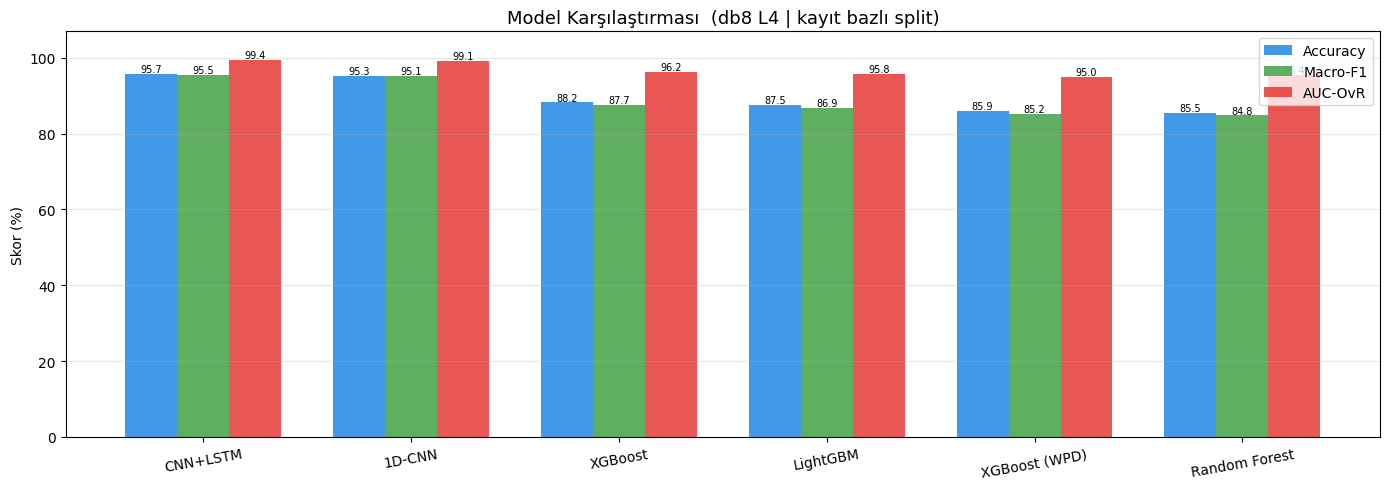

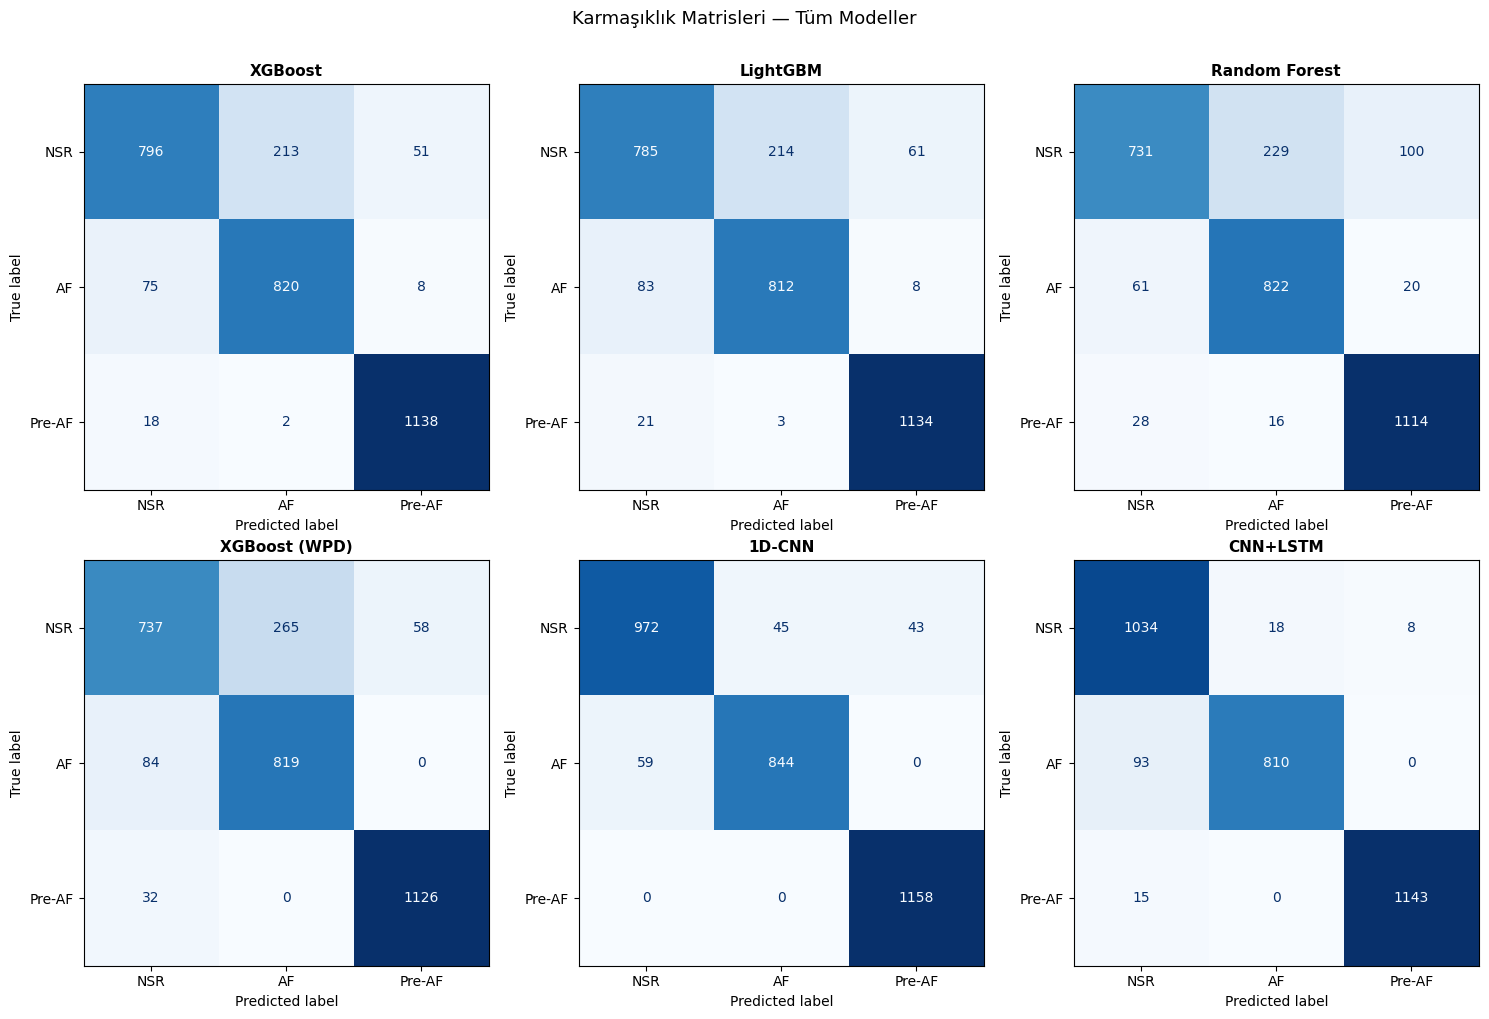


── [DÜZ-7] Karışma Analizi — 1D-CNN ────────────
  Karışma Matrisi (satır=gerçek, sütun=tahmin):
                   NSR        AF    Pre-AF
  NSR              972        45        43
  AF                59       844         0
  Pre-AF             0         0      1158

  NSR → AF yanlış sınıflandırma: 45 segment (%4.2)
  NSR → Pre-AF yanlış sınıflandırma: 43 segment (%4.1)
  AF → NSR yanlış sınıflandırma: 59 segment (%6.5)

  Klinik yorum:
    AF kaçırma oranı   : 59/903 (%6.5)
    Pre-AF kaçırma     : 0/1158 (%0.0)
    → AF kaçırmak klinik açıdan Pre-AF kaçırmaktan daha risklidir.


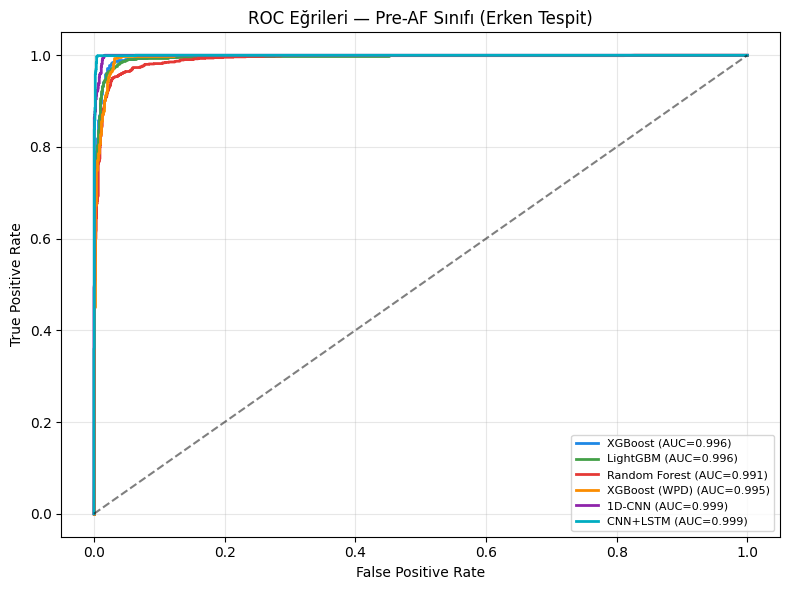

In [ ]:
# ════════════════════════════════════════════════════════
# HÜCRE 20 — Karşılaştırma Tablosu + ROC + Confusion Matrix
#            + [DÜZ-7] Karışma Analizi
# ════════════════════════════════════════════════════════
print("\n" + "="*55)
print("  KARŞILAŞTIRMA TABLOSU")
print("="*55)

rows_t = [{"Model":n, "Accuracy %":r["accuracy"], "Macro-F1 %":r["macro_f1"],
           "AUC-OvR %":r["auc_ovr"], "Süre (s)":r["train_sec"]}
          for n,r in RESULTS.items()]
df_res = pd.DataFrame(rows_t).sort_values("Macro-F1 %", ascending=False)
print(df_res.to_string(index=False))
df_res.to_csv(f"{OUTPUT_DIR}/model_comparison.csv", index=False)

# Bar grafik
fig, ax = plt.subplots(figsize=(14,5))
x = np.arange(len(df_res)); w = 0.25
ax.bar(x-w, df_res["Accuracy %"], w, label="Accuracy", color="#1E88E5", alpha=0.85)
ax.bar(x,   df_res["Macro-F1 %"], w, label="Macro-F1", color="#43A047", alpha=0.85)
ax.bar(x+w, df_res["AUC-OvR %"],  w, label="AUC-OvR",  color="#E53935", alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(df_res["Model"], fontsize=10, rotation=10)
ax.set_ylabel("Skor (%)"); ax.set_ylim(0,107)
ax.set_title(f"Model Karşılaştırması  ({WAVELET} L{DWT_LEVELS} | kayıt bazlı split)", fontsize=13)
ax.legend(); ax.grid(axis="y", alpha=0.3)
for i,(_,row) in enumerate(df_res.iterrows()):
    ax.text(i-w, row["Accuracy %"]+0.5, f'{row["Accuracy %"]:.1f}', ha="center", fontsize=7)
    ax.text(i,   row["Macro-F1 %"]+0.5, f'{row["Macro-F1 %"]:.1f}', ha="center", fontsize=7)
    ax.text(i+w, row["AUC-OvR %"]+0.5,  f'{row["AUC-OvR %"]:.1f}',  ha="center", fontsize=7)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/model_comparison_bar.png", dpi=150)
plt.show()

# Confusion matrix (tüm modeller)
n_m = len(RESULTS); cols = 3; rows_n = (n_m+cols-1)//cols
fig, axes = plt.subplots(rows_n, cols, figsize=(5*cols, 5*rows_n))
axes = axes.flatten()
for ax, (name, r) in zip(axes, RESULTS.items()):
    ConfusionMatrixDisplay(
        confusion_matrix(r["y_true"], r["y_pred"]),
        display_labels=CLASS_NAMES
    ).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name, fontsize=11, fontweight="bold")
for ax in axes[n_m:]:
    ax.set_visible(False)
fig.suptitle("Karmaşıklık Matrisleri — Tüm Modeller", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/confusion_matrices_all.png", dpi=150, bbox_inches="tight")
plt.show()

# ── [DÜZ-7] Karışma Analizi — en iyi model (1D-CNN) ────
print("\n── [DÜZ-7] Karışma Analizi — 1D-CNN ────────────")
if "1D-CNN" in RESULTS:
    r_cnn = RESULTS["1D-CNN"]
    cm = confusion_matrix(r_cnn["y_true"], r_cnn["y_pred"])
    total = cm.sum(axis=1)
    print("  Karışma Matrisi (satır=gerçek, sütun=tahmin):")
    print(f"  {'':10s}" + "".join(f"{c:>10s}" for c in CLASS_NAMES))
    for i, cls in enumerate(CLASS_NAMES):
        row_str = "".join(f"{cm[i,j]:>10d}" for j in range(3))
        print(f"  {cls:10s}{row_str}")
    print()
    for i, true_cls in enumerate(CLASS_NAMES):
        for j, pred_cls in enumerate(CLASS_NAMES):
            if i != j and cm[i,j] > 0:
                pct = cm[i,j]/total[i]*100
                print(f"  {true_cls} → {pred_cls} yanlış sınıflandırma: "
                      f"{cm[i,j]} segment (%{pct:.1f})")
    print()
    # Klinik yorum
    af_missed  = cm[1,0] + cm[1,2]  # AF → NSR veya Pre-AF
    af_total   = total[1]
    preaf_miss = cm[2,0] + cm[2,1]  # Pre-AF → NSR veya AF
    preaf_total= total[2]
    print(f"  Klinik yorum:")
    print(f"    AF kaçırma oranı   : {af_missed}/{af_total} (%{af_missed/af_total*100:.1f})")
    print(f"    Pre-AF kaçırma     : {preaf_miss}/{preaf_total} (%{preaf_miss/preaf_total*100:.1f})")
    print(f"    → AF kaçırmak klinik açıdan Pre-AF kaçırmaktan daha risklidir.")

# ROC eğrileri
fig, ax = plt.subplots(figsize=(8,6))
colors_roc = ["#1E88E5","#43A047","#E53935","#FB8C00","#8E24AA","#00ACC1"]
for (name,r), col in zip(RESULTS.items(), colors_roc):
    if r["proba"] is None: continue
    yb = label_binarize(r["y_true"], classes=[0,1,2])
    fpr, tpr, _ = roc_curve(yb[:,2], r["proba"][:,2])
    auc_val      = roc_auc_score(yb[:,2], r["proba"][:,2])
    ax.plot(fpr, tpr, color=col, lw=2, label=f"{name} (AUC={auc_val:.3f})")
ax.plot([0,1],[0,1],"k--",alpha=0.5)
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Eğrileri — Pre-AF Sınıfı (Erken Tespit)", fontsize=12)
ax.legend(loc="lower right", fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/roc_curves_preaf.png", dpi=150)
plt.show()

In [ ]:
# ════════════════════════════════════════════════════════
# HÜCRE 21 — McNemar İstatistiksel Test  [DÜZ-5]
#
# Model farkları istatistiksel olarak anlamlı mı?
# McNemar testi: iki modelin hangi örnekleri doğru/yanlış
# sınıflandırdığını karşılaştırır (bağımlı örnekler).
# p < 0.05 → fark istatistiksel olarak anlamlı.
# ════════════════════════════════════════════════════════
print("\n── McNemar İstatistiksel Test ───────────────────")
print("  H0: İki model arasında anlamlı fark yoktur")
print("  p < 0.05 → H0 reddedilir (fark anlamlı)\n")

model_names = list(RESULTS.keys())
ref_model   = "1D-CNN"  # en iyi model referans alındı

if ref_model in RESULTS:
    y_true_ref = RESULTS[ref_model]["y_true"]
    correct_ref = (RESULTS[ref_model]["y_pred"] == y_true_ref).astype(int)

    print(f"  Referans model: {ref_model}")
    print(f"  {'Model':20s}  {'n00':>6s}  {'n01':>6s}  {'n10':>6s}  {'n11':>6s}  {'p-değeri':>10s}  Sonuç")
    print("  " + "-"*80)

    mcnemar_results = {}
    for name in model_names:
        if name == ref_model:
            continue
        r = RESULTS[name]
        correct_b = (r["y_pred"] == r["y_true"]).astype(int)
        # Contingency table
        n00 = int(((correct_ref==0) & (correct_b==0)).sum())  # her ikisi yanlış
        n01 = int(((correct_ref==0) & (correct_b==1)).sum())  # ref yanlış, b doğru
        n10 = int(((correct_ref==1) & (correct_b==0)).sum())  # ref doğru, b yanlış
        n11 = int(((correct_ref==1) & (correct_b==1)).sum())  # her ikisi doğru
        table = np.array([[n11, n10], [n01, n00]])
        try:
            result = mcnemar(table, exact=False, correction=True)
            p_val  = result.pvalue
            sig    = "★ Anlamlı" if p_val < 0.05 else "  N.S."
        except Exception:
            p_val = float('nan'); sig = "  Hata"
        mcnemar_results[name] = {"p":p_val, "n10":n10, "n01":n01}
        print(f"  {name:20s}  {n00:>6d}  {n01:>6d}  {n10:>6d}  {n11:>6d}  {p_val:>10.4f}  {sig}")

    print("\n  Not: n10 = 1D-CNN doğru & diğer yanlış (1D-CNN avantajı)")
    print("       n01 = 1D-CNN yanlış & diğer doğru (diğer avantajı)")

print("\n✓ McNemar testi tamamlandı")


── McNemar İstatistiksel Test ───────────────────
  H0: İki model arasında anlamlı fark yoktur
  p < 0.05 → H0 reddedilir (fark anlamlı)

  Referans model: 1D-CNN
  Model                    n00     n01     n10     n11    p-değeri  Sonuç
  --------------------------------------------------------------------------------
  XGBoost                   64      83     303    2671      0.0000  ★ Anlamlı
  LightGBM                  67      80     323    2651      0.0000  ★ Anlamlı
  Random Forest             66      81     388    2586      0.0000  ★ Anlamlı
  XGBoost (WPD)             78      69     361    2613      0.0000  ★ Anlamlı
  CNN+LSTM                  51      96      83    2891      0.3698    N.S.

  Not: n10 = 1D-CNN doğru & diğer yanlış (1D-CNN avantajı)
       n01 = 1D-CNN yanlış & diğer doğru (diğer avantajı)

✓ McNemar testi tamamlandı


In [ ]:
# ════════════════════════════════════════════════════════
# HÜCRE 22 — Erken Tespit: Ana Deneyle Birleşik Analiz  [YENİ-2]
#
# Önceki sürümde erken tespit ayrı bir GroupShuffleSplit ve
# ayrı bir ikili XGBoost modeli kullanıyordu. Bu sürümde:
#   - Ana deneyin TEST_IDX üzerinde Pre-AF segmentleri filtrelenir
#   - Ana modelin (XGBoost) mevcut test tahminleri kullanılır
#   - mins_to_af değerine göre dakika bazlı doğruluk hesaplanır
# Avantaj: Tek split, tutarlı metodoloji, iki deneyin sonuçları
# doğrudan karşılaştırılabilir.
# ════════════════════════════════════════════════════════
print("\n" + "="*55)
print("  ERKEN TESPİT — ANA DENEYLE BİRLEŞİK  [YENİ-2]")
print("="*55)

# Ana modelin test seti tahminlerini al (XGBoost en hızlı ve yorumlanabilir)
if "XGBoost" not in RESULTS:
    raise RuntimeError("Hücre 16'yı önce çalıştırın (XGBoost modeli gerekli).")

r_xgb     = RESULTS["XGBoost"]
y_true_te = r_xgb["y_true"]
y_pred_te = r_xgb["y_pred"]
proba_te  = r_xgb["proba"]

# Test setindeki her segmentin meta bilgisini al
test_meta = [bal_meta[i] for i in TEST_IDX]

# Pre-AF segmentlerini filtrele (label=2) + mins_to_af değeri olan
preaf_indices = [
    i for i, (lbl, m) in enumerate(zip(y_true_te, test_meta))
    if lbl == 2 and m.get("mins_to_af") is not None
]

print(f"  Test setinde mins_to_af değeri olan Pre-AF segmenti: {len(preaf_indices)}")

if len(preaf_indices) == 0:
    print("  ⚠ AFPDB'den gelen Pre-AF yakın (p*c) segmenti test setinde yok.")
    print("  Bu, alt örnekleme sırasında bu segmentlerin seçilmediği anlamına gelebilir.")
    print("  Orijinal (dengeli olmayan) veri üzerinden analiz yapılıyor...")

    # Fallback: orijinal all_segs üzerinden filtrele
    fallback_rows = []
    for seg, orig_lbl, m in zip(all_segs, all_labels, all_meta):
        if orig_lbl == 3 and m.get("mins_to_af") is not None:
            row = extract_dwt_features(seg)
            row["mins_to_af"] = m["mins_to_af"]
            row["record"]     = m["record"]
            row["label"]      = 3
            fallback_rows.append(row)
        elif orig_lbl == 0 and m.get("source") == "AFPDB":
            row = extract_dwt_features(seg)
            row["mins_to_af"] = None
            row["record"]     = m["record"]
            row["label"]      = 0
            fallback_rows.append(row)

    df_fb   = pd.DataFrame(fallback_rows)
    FEAT_FB = [c for c in df_fb.columns if c not in ["label","mins_to_af","record"]]
    fb_recs = np.array([r["record"] for r in fallback_rows])

    gss_fb = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_SEED)
    fb_tr, fb_te = next(gss_fb.split(np.arange(len(df_fb)),
                                      df_fb["label"].values, groups=fb_recs))
    overlap_fb = set(fb_recs[fb_tr]) & set(fb_recs[fb_te])
    print(f"  Fallback split — Eğitim: {len(fb_tr)}, Test: {len(fb_te)}, "
          f"Örtüşme: {len(overlap_fb)} ({'✓' if len(overlap_fb)==0 else '✗'})")

    df_bin_tr = df_fb.iloc[fb_tr][df_fb.iloc[fb_tr]["label"].isin([0,3])].copy()
    df_bin_te = df_fb.iloc[fb_te][df_fb.iloc[fb_te]["label"]==3].copy()

    sc_fb  = StandardScaler()
    X_fb_tr = sc_fb.fit_transform(df_bin_tr[FEAT_FB].values.astype(np.float32))
    y_fb_tr = (df_bin_tr["label"]==3).astype(int).values

    model_fb = xgb.XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                                   eval_metric="logloss",
                                   random_state=RANDOM_SEED, n_jobs=-1, verbosity=0)
    model_fb.fit(X_fb_tr, y_fb_tr)

    X_fb_te = sc_fb.transform(df_bin_te[FEAT_FB].values.astype(np.float32))
    preds_fb = model_fb.predict(X_fb_te)
    probs_fb = model_fb.predict_proba(X_fb_te)[:,1]
    df_bin_te = df_bin_te.copy()
    df_bin_te["predicted"]  = preds_fb
    df_bin_te["confidence"] = probs_fb
    df_ce = df_bin_te
    use_fallback = True
    print("  ⚠ Fallback modu kullanıldı — metodoloji notu bildiride belirtilmeli.")
else:
    # Ana modelin tahminlerinden dakika bazlı analiz
    use_fallback = False
    records_list = []
    for idx in preaf_indices:
        records_list.append({
            "mins_to_af" : test_meta[idx]["mins_to_af"],
            "predicted"  : int(y_pred_te[idx] == 2),   # 1: Pre-AF olarak doğru tahmin
            "confidence" : float(proba_te[idx][2]),     # Pre-AF sınıfı olasılığı
            "true_label" : int(y_true_te[idx]),
            "pred_label" : int(y_pred_te[idx]),
        })
    df_ce = pd.DataFrame(records_list)
    print(f"  Ana model (XGBoost) üzerinden analiz yapılıyor.")
    print(f"  Pre-AF doğru tespit: {df_ce['predicted'].sum()} / {len(df_ce)}")

# Dakika bazlı analiz
time_bins  = [0,1,2,3,4,5]
bin_labels_t = ["0-1 dk","1-2 dk","2-3 dk","3-4 dk","4-5 dk"]
accuracies, counts = [], []

print("\nDakika bazlı tespit oranı:")
for lo, hi in zip(time_bins[:-1], time_bins[1:]):
    mask   = (df_ce["mins_to_af"] >= lo) & (df_ce["mins_to_af"] < hi)
    subset = df_ce[mask]
    if len(subset) < 3:
        accuracies.append(None); counts.append(0); continue
    acc = subset["predicted"].mean() * 100
    accuracies.append(round(acc,1)); counts.append(len(subset))
    print(f"  {bin_labels_t[lo]:8s}: %{acc:.1f}  ({len(subset)} segment)")

# Genel istatistikler
correct    = df_ce[df_ce["predicted"]==1]
high_conf  = correct[correct["confidence"]>=0.90] if "confidence" in correct.columns else correct

from statsmodels.stats.proportion import proportion_confint
n_correct = int(df_ce["predicted"].sum())
n_total   = len(df_ce)
ci_low, ci_high = proportion_confint(n_correct, n_total, alpha=0.05, method="wilson")

print(f"\n  Genel tespit oranı : %{n_correct/n_total*100:.1f}")
print(f"  95% CI            : %{ci_low*100:.1f} – %{ci_high*100:.1f}")
if len(correct) > 0:
    print(f"  Ort. tespit süresi : AF'den {correct['mins_to_af'].mean():.1f} dk önce")
    print(f"  En erken tespit    : AF'den {correct['mins_to_af'].max():.1f} dk önce")
if len(high_conf) > 0:
    print(f"  Yüksek güven ≥0.90 : AF'den {high_conf['mins_to_af'].mean():.1f} dk önce")

method_note = "Fallback (AFPDB ikili split)" if use_fallback else "Ana deneyle birleşik (TEST_IDX)"
print(f"\n  Metodoloji: {method_note}  [YENİ-2]")



  ERKEN TESPİT — ANA DENEYLE BİRLEŞİK  [YENİ-2]
  Test setinde mins_to_af değeri olan Pre-AF segmenti: 287
  Ana model (XGBoost) üzerinden analiz yapılıyor.
  Pre-AF doğru tespit: 278 / 287

Dakika bazlı tespit oranı:
  0-1 dk  : %96.7  (60 segment)
  1-2 dk  : %97.7  (43 segment)
  2-3 dk  : %98.1  (52 segment)
  3-4 dk  : %94.1  (68 segment)
  4-5 dk  : %100.0  (59 segment)

  Genel tespit oranı : %96.9
  95% CI            : %94.1 – %98.3
  Ort. tespit süresi : AF'den 2.6 dk önce
  En erken tespit    : AF'den 5.0 dk önce
  Yüksek güven ≥0.90 : AF'den 2.6 dk önce

  Metodoloji: Ana deneyle birleşik (TEST_IDX)  [YENİ-2]


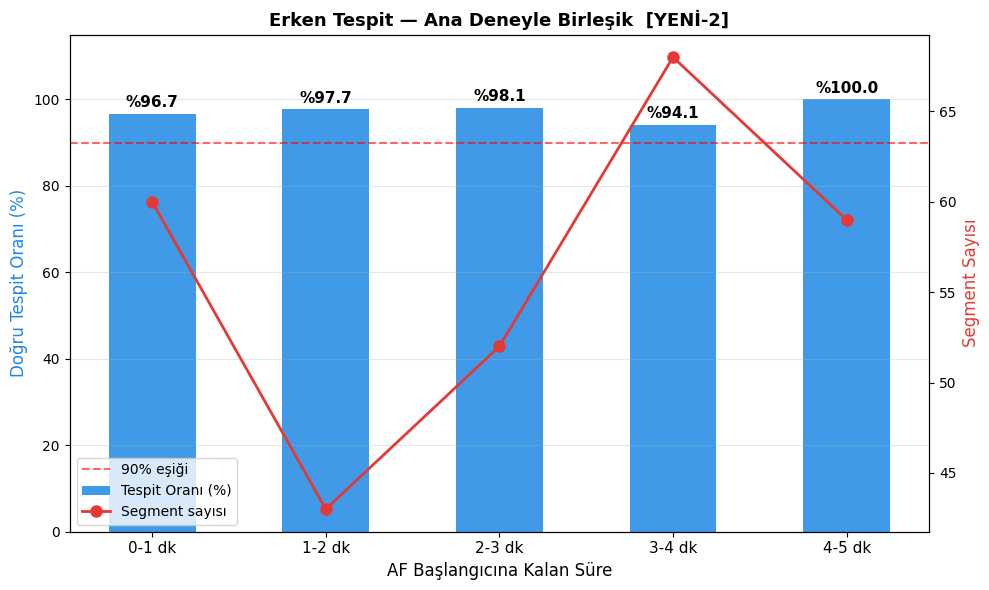


════════════════════════════════════════════════════════════════
  ERKEN TESPİT ÖZETI  [ANA DENEYLE BİRLEŞİK — YENİ-2]
════════════════════════════════════════════════════════════════
  Test Pre-AF yakın segment : 287
  Doğru tespit              : 278  (96.9%)
  95% CI                    : %94.1 – %98.3
  Ort. tespit süresi        : AF'den 2.6 dk önce
  En erken tespit           : AF'den 5.0 dk önce
  Yüksek güven (≥0.90)      : AF'den 2.6 dk önce

════════════════════════════════════════════════════════════════
  TÜM MODELLER  [db8 L4 | kayıt bazlı]
════════════════════════════════════════════════════════════════
        Model  Accuracy %  Macro-F1 %  AUC-OvR %  Süre (s)
     CNN+LSTM       95.71       95.50      99.42      76.6
       1D-CNN       95.29       95.11      99.13      24.1
      XGBoost       88.24       87.65      96.21       1.9
     LightGBM       87.50       86.89      95.82       1.4
XGBoost (WPD)       85.93       85.21      94.95       2.6
Random Forest       85.

In [ ]:
# ════════════════════════════════════════════════════════
# HÜCRE 23 — Erken Tespit Grafikleri & Final Özet
# ════════════════════════════════════════════════════════

valid = [(bl,ac,cn) for bl,ac,cn in zip(bin_labels_t,accuracies,counts) if ac is not None]
x_lb  = [v[0] for v in valid]
y_ac  = [v[1] for v in valid]
y_cn  = [v[2] for v in valid]
x_pos = np.arange(len(x_lb))

fig, ax1 = plt.subplots(figsize=(10,6))
bars = ax1.bar(x_pos, y_ac, color="#1E88E5", alpha=0.85, width=0.5,
               label="Tespit Oranı (%)")
ax1.set_xlabel("AF Başlangıcına Kalan Süre", fontsize=12)
ax1.set_ylabel("Doğru Tespit Oranı (%)", fontsize=12, color="#1E88E5")
ax1.set_xticks(x_pos); ax1.set_xticklabels(x_lb, fontsize=11)
ax1.set_ylim(0,115)
ax1.axhline(y=90, color="red", linestyle="--", alpha=0.6, label="90% eşiği")
for bar, acc in zip(bars, y_ac):
    ax1.text(bar.get_x()+bar.get_width()/2, acc+1.5,
             f"%{acc}", ha="center", fontsize=11, fontweight="bold")
ax2 = ax1.twinx()
ax2.plot(x_pos, y_cn, "o-", color="#E53935", lw=2, ms=8, label="Segment sayısı")
ax2.set_ylabel("Segment Sayısı", fontsize=12, color="#E53935")
ln1,lb1 = ax1.get_legend_handles_labels()
ln2,lb2 = ax2.get_legend_handles_labels()
ax1.legend(ln1+ln2, lb1+lb2, loc="lower left", fontsize=10)
ax1.set_title("Erken Tespit — Ana Deneyle Birleşik  [YENİ-2]",
              fontsize=13, fontweight="bold")
ax1.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/early_detection_by_time.png", dpi=150)
plt.show()

# ── Final Özet ─────────────────────────────────────────
print("\n" + "═"*64)
print("  ERKEN TESPİT ÖZETI  [ANA DENEYLE BİRLEŞİK — YENİ-2]")
print("═"*64)
print(f"  Test Pre-AF yakın segment : {n_total:,}")
print(f"  Doğru tespit              : {n_correct:,}  ({n_correct/max(n_total,1)*100:.1f}%)")
print(f"  95% CI                    : %{ci_low*100:.1f} – %{ci_high*100:.1f}")
if len(correct) > 0:
    print(f"  Ort. tespit süresi        : AF'den {correct['mins_to_af'].mean():.1f} dk önce")
    print(f"  En erken tespit           : AF'den {correct['mins_to_af'].max():.1f} dk önce")
if len(high_conf) > 0:
    print(f"  Yüksek güven (≥0.90)      : AF'den {high_conf['mins_to_af'].mean():.1f} dk önce")

print("\n" + "═"*64)
print(f"  TÜM MODELLER  [{WAVELET} L{DWT_LEVELS} | kayıt bazlı]")
print("═"*64)
print(df_res.to_string(index=False))

print("\n" + "═"*64)
print("  ABLASYON → UYGULANAN PARAMETRELER")
print("═"*64)
print(f"  Seçilen wavelet : {WAVELET}  (ablasyonda en iyi: {best_wv}  ← {'eşleşti ✓' if WAVELET==best_wv else 'farklı ✗'})")
print(f"  Seçilen seviye  : L{DWT_LEVELS}  (ablasyonda en iyi: L{best_lv}  ← {'eşleşti ✓' if DWT_LEVELS==best_lv else 'farklı ✗'})")
print(f"  DWT öznitelik   : {len(FEAT_COLS)}  ({DWT_LEVELS+1} bant × 5 istatistik)")

print("\n  GroupKFold CV:")
for n,r in cv_results.items():
    print(f"    {n:15s}: {r['mean']:.2f}% ± {r['std']:.2f}%")

print("\n" + "═"*64)
print("  DWT vs WPD ADİL KARŞILAŞTIRMA  [YENİ-3]")
print("═"*64)
for method, res in fair_results.items():
    print(f"  {method}: en iyi F1={res['best_f1']}%  (depth={res['best_depth']})")
delta_final = fair_results["DWT"]["best_f1"] - fair_results["WPD"]["best_f1"]
print(f"  Kazanan: {'DWT' if delta_final>0 else 'WPD'}  ΔF1={abs(delta_final):.2f} puan")


print("\n  UYGULANAN TÜM DEĞİŞİKLİKLER:")
print("  [DÜZ-1] WAVELET = db8")
print("  [DÜZ-2] DWT_LEVELS = 4  (L4>L5 tutarsızlığı giderildi)")
print("  [DÜZ-3] GroupShuffleSplit + GroupKFold  (kayıt bazlı)")
print("  [DÜZ-4] SVM kaldırıldı")
print("  [DÜZ-5] McNemar istatistiksel test")
print("  [DÜZ-6] SHAP sayısal çıktısı + heatmap")
print("  [DÜZ-7] Confusion matrix karışma analizi")
print("  [DÜZ-8] CWT metodoloji notu")
print("  [DÜZ-8] CWT öznitelik çıkarımından kaldırıldı — sadece görsel doğrulama")
print("  [YENİ-2] Erken tespit ana deneyle birleştirildi")
print("  [YENİ-3] DWT vs WPD adil karşılaştırma (depth opt.)")
print(f"\n✓ Tüm çıktılar kaydedildi → {OUTPUT_DIR}/")
